In [ ]:
!pip install librosa matplotlib numpy

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
print(uploaded.keys())

In [ ]:
recordings = {}

for filename in uploaded.keys():
    audio, sr = librosa.load(filename, sr=None)
    recordings[filename] = (audio, sr)

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
recordings = {}

for filename in uploaded.keys():
    audio, sr = librosa.load(filename, sr=None)
    recordings[filename] = (audio, sr)

In [ ]:
for filename, (audio, sr) in recordings.items():
    print(filename)
    print("Sample rate:", sr)
    print("Duration:", len(audio) / sr, "seconds")
    print()

In [ ]:
for filename, (audio, sr) in recordings.items():

    plt.figure(figsize=(14, 4))

    librosa.display.waveshow(audio, sr=sr)

    plt.title(filename)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")

    plt.show()

In [ ]:
for filename, (audio, sr) in recordings.items():

    D = librosa.stft(audio, n_fft=2048, hop_length=512)

    S_db = librosa.amplitude_to_db(
        np.abs(D),
        ref=np.max
    )

    plt.figure(figsize=(14, 5))

    librosa.display.specshow(
        S_db,
        sr=sr,
        hop_length=512,
        x_axis="time",
        y_axis="hz"
    )

    plt.colorbar(format="%+2.0f dB")
    plt.ylim(0, 8000)
    plt.title(filename + " — Spectrogram")
    plt.show()

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

filenames = [
    "New Project - Lower.wav",
    "New Project - Higher.wav",
    "New Project - Normal.wav"
]

recordings = {}

for filename in filenames:
    audio, sr = librosa.load(filename, sr=None)
    recordings[filename] = (audio, sr)

print("All recordings loaded!")

In [ ]:

# ==========================================
# VOCAL TIMING COACH — INITIAL AUDIO ANALYSIS
# ==========================================

# 1. Import libraries
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from pathlib import Path
import zipfile

# 2. Upload recordings
uploaded = files.upload()

# 3. Create output folder
output_folder = Path("Vocal_Timing_Analysis")
output_folder.mkdir(exist_ok=True)

recordings = {}

# 4. Load and analyse every recording
for filename in uploaded.keys():

    print(f"\nAnalysing: {filename}")

    audio, sr = librosa.load(filename, sr=None)
    recordings[filename] = (audio, sr)

    # Spectrogram
    D = librosa.stft(audio, n_fft=2048, hop_length=512)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    # RMS energy
    rms = librosa.feature.rms(
        y=audio,
        frame_length=2048,
        hop_length=512
    )[0]

    # Zero-crossing rate
    zcr = librosa.feature.zero_crossing_rate(
        audio,
        frame_length=2048,
        hop_length=512
    )[0]

    # Spectral centroid
    centroid = librosa.feature.spectral_centroid(
        y=audio,
        sr=sr,
        n_fft=2048,
        hop_length=512
    )[0]

    # Time values for feature plots
    times = librosa.frames_to_time(
        np.arange(len(rms)),
        sr=sr,
        hop_length=512
    )

    # 5. Generate a five-panel analysis figure
    fig, axes = plt.subplots(5, 1, figsize=(15, 20))

    # Waveform
    librosa.display.waveshow(audio, sr=sr, ax=axes[0])
    axes[0].set_title("1. Waveform")
    axes[0].set_ylabel("Amplitude")

    # Spectrogram
    img = librosa.display.specshow(
        S_db,
        sr=sr,
        hop_length=512,
        x_axis="time",
        y_axis="hz",
        ax=axes[1]
    )
    axes[1].set_ylim(0, 8000)
    axes[1].set_title("2. Spectrogram")
    fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

    # RMS
    axes[2].plot(times, rms)
    axes[2].set_title("3. RMS Energy")
    axes[2].set_ylabel("Energy")

    # ZCR
    axes[3].plot(times, zcr)
    axes[3].set_title("4. Zero-Crossing Rate")
    axes[3].set_ylabel("Rate")

    # Spectral centroid
    axes[4].plot(times, centroid)
    axes[4].set_title("5. Spectral Centroid")
    axes[4].set_ylabel("Frequency (Hz)")
    axes[4].set_xlabel("Time (seconds)")

    fig.suptitle(filename, fontsize=16)
    plt.tight_layout()

    # 6. Save figure
    safe_name = Path(filename).stem.replace(" ", "_")
    save_path = output_folder / f"{safe_name}_analysis.png"

    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Saved: {save_path}")

# 7. Package all analysis images into one ZIP
zip_path = "Vocal_Timing_Analysis.zip"

with zipfile.ZipFile(zip_path, "w") as zip_file:
    for image_path in output_folder.glob("*.png"):
        zip_file.write(image_path, arcname=image_path.name)

print("\nALL ANALYSES COMPLETE!")

# 8. Download the ZIP
files.download(zip_path)


In [ ]:

# =========================================
# EXPERIMENT 1: THREE "SEE" REPETITIONS
# Normal → Higher → Lower
# =========================================

import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from pathlib import Path

# 1. Upload the recording
uploaded = files.upload()

filename = next(iter(uploaded.keys()))

# 2. Load audio
audio, sr = librosa.load(filename, sr=None)

print("File:", filename)
print("Sample rate:", sr, "Hz")
print("Duration:", round(len(audio) / sr, 2), "seconds")

# 3. Set analysis parameters
n_fft = 2048
hop_length = 256

# 4. Calculate spectrogram
D = librosa.stft(
    audio,
    n_fft=n_fft,
    hop_length=hop_length
)

S_db = librosa.amplitude_to_db(
    np.abs(D),
    ref=np.max
)

# 5. Calculate RMS energy
rms = librosa.feature.rms(
    y=audio,
    frame_length=n_fft,
    hop_length=hop_length
)[0]

# 6. Calculate zero-crossing rate
zcr = librosa.feature.zero_crossing_rate(
    audio,
    frame_length=n_fft,
    hop_length=hop_length
)[0]

# 7. Calculate spectral centroid
centroid = librosa.feature.spectral_centroid(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)[0]

# 8. Calculate time axis
times = librosa.frames_to_time(
    np.arange(len(rms)),
    sr=sr,
    hop_length=hop_length
)

# 9. Generate all five plots
fig, axes = plt.subplots(5, 1, figsize=(16, 18))

# Waveform
librosa.display.waveshow(audio, sr=sr, ax=axes[0])
axes[0].set_title("1. Waveform")
axes[0].set_ylabel("Amplitude")

# Spectrogram
img = librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz",
    ax=axes[1]
)
axes[1].set_ylim(0, 8000)
axes[1].set_title("2. Spectrogram")
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

# RMS
axes[2].plot(times, rms)
axes[2].set_title("3. RMS Energy")
axes[2].set_ylabel("Energy")

# ZCR
axes[3].plot(times, zcr)
axes[3].set_title("4. Zero-Crossing Rate")
axes[3].set_ylabel("Rate")

# Spectral centroid
axes[4].plot(times, centroid)
axes[4].set_title("5. Spectral Centroid")
axes[4].set_ylabel("Frequency (Hz)")
axes[4].set_xlabel("Time (seconds)")

fig.suptitle("SEE — Normal, Higher and Lower Pitch", fontsize=16)

plt.tight_layout()

# 10. Save analysis
output_path = "See_Three_Pitches_Analysis.png"

plt.savefig(
    output_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Analysis saved:", output_path)

# 11. Download analysis
files.download(output_path)


In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import librosa

filename = next(iter(uploaded))

audio, sr = librosa.load(filename, sr=None)

print("Loaded:", filename)
print("Sample rate:", sr)
print("Duration:", len(audio) / sr, "seconds")

In [ ]:
# 3. Set analysis parameters
n_fft = 2048
hop_length = 256

# 4. Calculate spectrogram
D = librosa.stft(
    audio,
    n_fft=n_fft,
    hop_length=hop_length
)

S_db = librosa.amplitude_to_db(
    np.abs(D),
    ref=np.max
)

# 5. Calculate RMS energy
rms = librosa.feature.rms(
    y=audio,
    frame_length=n_fft,
    hop_length=hop_length
)[0]

# 6. Calculate zero-crossing rate
zcr = librosa.feature.zero_crossing_rate(
    audio,
    frame_length=n_fft,
    hop_length=hop_length
)[0]

# 7. Calculate spectral centroid
centroid = librosa.feature.spectral_centroid(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)[0]

# 8. Calculate time axis
times = librosa.frames_to_time(
    np.arange(len(rms)),
    sr=sr,
    hop_length=hop_length
)

# 9. Generate all five plots
fig, axes = plt.subplots(5, 1, figsize=(16, 18))

# Waveform
librosa.display.waveshow(audio, sr=sr, ax=axes[0])
axes[0].set_title("1. Waveform")
axes[0].set_ylabel("Amplitude")

# Spectrogram
img = librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz",
    ax=axes[1]
)
axes[1].set_ylim(0, 8000)
axes[1].set_title("2. Spectrogram")
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

# RMS
axes[2].plot(times, rms)
axes[2].set_title("3. RMS Energy")
axes[2].set_ylabel("Energy")

# ZCR
axes[3].plot(times, zcr)
axes[3].set_title("4. Zero-Crossing Rate")
axes[3].set_ylabel("Rate")

# Spectral centroid
axes[4].plot(times, centroid)
axes[4].set_title("5. Spectral Centroid")
axes[4].set_ylabel("Frequency (Hz)")
axes[4].set_xlabel("Time (seconds)")

fig.suptitle("SEE — Normal, Higher and Lower Pitch", fontsize=16)

plt.tight_layout()

# 10. Save analysis
output_path = "See_Three_Pitches_Analysis.png"

plt.savefig(
    output_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Analysis saved:", output_path)

# 11. Download analysis
files.download(output_path)


In [ ]:
# 3. Set analysis parameters
n_fft = 2048
hop_length = 256

# 4. Calculate spectrogram
D = librosa.stft(
    audio,
    n_fft=n_fft,
    hop_length=hop_length
)

S_db = librosa.amplitude_to_db(
    np.abs(D),
    ref=np.max
)

# 5. Calculate RMS energy
rms = librosa.feature.rms(
    y=audio,
    frame_length=n_fft,
    hop_length=hop_length
)[0]

# 6. Calculate zero-crossing rate
zcr = librosa.feature.zero_crossing_rate(
    audio,
    frame_length=n_fft,
    hop_length=hop_length
)[0]

# 7. Calculate spectral centroid
centroid = librosa.feature.spectral_centroid(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)[0]

# 8. Calculate time axis
times = librosa.frames_to_time(
    np.arange(len(rms)),
    sr=sr,
    hop_length=hop_length
)

# 9. Generate all five plots
fig, axes = plt.subplots(5, 1, figsize=(16, 18))

# Waveform
librosa.display.waveshow(audio, sr=sr, ax=axes[0])
axes[0].set_title("1. Waveform")
axes[0].set_ylabel("Amplitude")

# Spectrogram
img = librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz",
    ax=axes[1]
)
axes[1].set_ylim(0, 8000)
axes[1].set_title("2. Spectrogram")
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

# RMS
axes[2].plot(times, rms)
axes[2].set_title("3. RMS Energy")
axes[2].set_ylabel("Energy")

# ZCR
axes[3].plot(times, zcr)
axes[3].set_title("4. Zero-Crossing Rate")
axes[3].set_ylabel("Rate")

# Spectral centroid
axes[4].plot(times, centroid)
axes[4].set_title("5. Spectral Centroid")
axes[4].set_ylabel("Frequency (Hz)")
axes[4].set_xlabel("Time (seconds)")

fig.suptitle("SEE — Normal, Higher and Lower Pitch", fontsize=16)

plt.tight_layout()

# 10. Save analysis
output_path = "See_Three_Pitches_Analysis.png"

plt.savefig(
    output_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Analysis saved:", output_path)

# 11. Download analysis
files.download(output_path)


In [ ]:
from google.colab import files
import json
from bournemouth_aligner import PhonemeTimestampAligner

# Upload your test audio clip (or use an existing path if uploaded to Drive)
uploaded = files.upload()
audio_path = list(uploaded.keys())[0]

# Initialize the aligner
aligner = PhonemeTimestampAligner(preset="en-us")

# Enter the exact lyrics/transcript of your audio clip
transcript = "Put your exact lyrics here"
result = aligner.process_sentence(transcript, audio_path)

# Extract and inspect phoneme/vowel onsets
print("--- Phoneme Timestamps ---")
for p in result.get("phoneme_ts", []):
    print(f"Phoneme: {p['ipa_label']:<4} | Start: {p['start_ms']:>5} ms | End: {p['end_ms']:>5} ms")

In [ ]:
# 1. Install system dependencies and the package quietly
print("Installing dependencies and Bournemouth Forced Aligner...")
!apt-get update -qq && apt-get install -y -qq espeak-ng ffmpeg
!pip install -q bournemouth-forced-aligner

# 2. Run the test script
import json
from google.colab import files
from bournemouth_aligner import PhonemeTimestampAligner

print("\nSetup complete! Please upload a short audio clip (.wav or .mp3):")
uploaded = files.upload()
audio_path = list(uploaded.keys())[0]

# Initialize the aligner for American English
aligner = PhonemeTimestampAligner(preset="en-us")

# Type the exact lyrics or spoken text for your clip here
transcript = "Put your exact lyrics here"
result = aligner.process_sentence(transcript, audio_path)

# Print the resulting phoneme timestamps
print("\n--- Phoneme Timestamps ---")
for p in result.get("phoneme_ts", []):
    print(f"Phoneme: {p['ipa_label']:<4} | Start: {p['start_ms']:>5} ms | End: {p['end_ms']:>5} ms | Confidence: {p['confidence']:.2f}")

In [ ]:
# 1. Force reinstall the latest version to grab PhonemeTimestampAligner
print("Installing/Upgrading dependencies and Bournemouth Forced Aligner...")
!apt-get update -qq && apt-get install -y -qq espeak-ng ffmpeg
!pip install --upgrade --force-reinstall -q bournemouth-forced-aligner

# 2. Clear module cache if needed and import
import sys
if 'bournemouth_aligner' in sys.modules:
    del sys.modules['bournemouth_aligner']

import json
from google.colab import files
from bournemouth_aligner import PhonemeTimestampAligner

print("\nSetup complete! Please upload your short audio clip (.wav or .mp3):")
uploaded = files.upload()
audio_path = list(uploaded.keys())[0]

# Initialize the aligner for American English
aligner = PhonemeTimestampAligner(preset="en-us")

# Type the exact lyrics or spoken text for your clip here
transcript = "Put your exact lyrics here"
audio = aligner.load_audio(audio_path)
result = aligner.process_sentence(transcript, audio)

# Print the resulting phoneme timestamps
print("\n--- Phoneme Timestamps ---")
for p in result.get("phoneme_ts", []):
    print(f"Phoneme: {p['ipa_label']:<4} | Start: {p['start_ms']:>5} ms | End: {p['end_ms']:>5} ms | Confidence: {p['confidence']:.2f}")

In [ ]:
# 1. Install system dependencies and the latest BFA package directly from GitHub
print("Installing dependencies and Bournemouth Forced Aligner...")
!apt-get update -qq && apt-get install -y -qq espeak-ng ffmpeg
!pip install -q git+https://github.com/tabahi/bournemouth-forced-aligner.git

# 2. Upload your test audio file (.wav or .mp3)
from google.colab import files
print("\nPlease upload your short audio clip:")
uploaded = files.upload()
audio_filename = list(uploaded.keys())[0]

# 3. Set your exact transcript/lyrics here
transcript = "Put your exact lyrics here"

# 4. Run alignment using the native CLI command (generates a .vs.json file)
print(f"\nAligning '{audio_filename}'...")
!balign "{audio_filename}" "{transcript}" --preset=en-us

# 5. Load and display the generated JSON timestamps
import json
import glob

json_files = glob.glob("*.vs.json")
if json_files:
    json_path = json_files[0]
    print(f"\nReading timestamps from {json_path}:\n")
    with open(json_path, "r") as f:
        result = json.load(f)

    for p in result.get("phoneme_ts", []):
        print(f"Phoneme: {p['ipa_label']:<4} | Start: {p['start_ms']:>5} ms | End: {p['end_ms']:>5} ms | Confidence: {p['confidence']:.2f}")
else:
    print("Error: Alignment output JSON file was not generated.")

In [ ]:
import json
import glob

# Find the generated JSON file
json_files = glob.glob("*.vs.json")
if json_files:
    with open(json_files[0], "r") as f:
        data = json.load(f)

    # Common English vowel phoneme symbols (or check BFA's group categorization if available)
    # Depending on the IPA set used, you can refine these or check data["group_ts"]
    vowel_symbols = {"i", "ɪ", "e", "ɛ", "æ", "ɑ", "ɔ", "ʊ", "u", "ʌ", "ə", "eɪ", "aɪ", "oʊ", "aʊ", "ɔɪ"}

    print("--- Extracted Vowel Onsets ---")
    vowel_onsets = []

    # BFA usually organizes data by words -> phonemes, or a flat list of phoneme_ts
    for p in data.get("phoneme_ts", []):
        ipa = p["ipa_label"].strip()
        # Check if the phoneme is a vowel (or check BFA's category/group data)
        if any(v in ipa for v in ["i", "e", "a", "o", "u", "æ", "ɑ", "ɔ", "ɪ", "ʊ", "ʌ", "ə"]):
            start_ms = p["start_ms"]
            vowel_onsets.append({"phoneme": ipa, "start_ms": start_ms})
            print(f"Vowel: {ipa:<3} | Onset Time: {start_ms:>5} ms")

    print(f"\nTotal vowel onsets found: {len(vowel_onsets)}")
else:
    print("No alignment JSON found. Run the alignment step first!")

In [ ]:
import json
import glob

# Find the generated JSON file
json_files = glob.glob("*.vs.json")
if json_files:
    with open(json_files[0], "r") as f:
        data = json.load(f)

    vowel_onsets = []

    # BFA nests phoneme timestamps inside the 'segments' list
    for segment in data.get("segments", []):
        for p in segment.get("phoneme_ts", []):
            ipa = p.get("ipa_label", "").strip()

            # Check against common vowel IPA symbols
            if any(v in ipa for v in ["i", "e", "a", "o", "u", "æ", "ɑ", "ɔ", "ɪ", "ʊ", "ʌ", "ə", "ɝ", "ɚ"]):
                start_ms = p.get("start_ms")
                vowel_onsets.append({"phoneme": ipa, "start_ms": start_ms})
                print(f"Vowel: {ipa:<4} | Start: {start_ms:>5} ms | Confidence: {p.get('confidence', 0):.2f}")

    print(f"\nTotal vowel onsets successfully found: {len(vowel_onsets)}")
else:
    print("Error: No alignment JSON file found. Make sure the alignment step ran successfully!")

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
filename = next(iter(uploaded))

print("Uploaded:", filename)

In [ ]:
import librosa

audio, sr = librosa.load(filename, sr=None)

print("Sample rate:", sr)
print("Duration:", len(audio) / sr, "seconds")

In [ ]:
!pip install singalign

In [ ]:
!pip install uv
!git clone https://github.com/pymaster17/SingAlign.git

In [ ]:
%cd /content/SingAlign
!uv sync

In [ ]:
!uv sync --extra pitch

In [ ]:
import os

print(os.listdir('/content'))

In [ ]:
!git clone https://github.com/facebookresearch/singalign.git /content/SingAlign

In [ ]:
!git clone https://github.com/pymaster17/SingAlign.git /content/SingAlign

In [ ]:
!wget -O /content/SingAlign.zip https://github.com/pymaster17/SingAlign/archive/refs/heads/main.zip
!unzip -q /content/SingAlign.zip -d /content/

In [ ]:
!pip install -q huggingface_hub

from huggingface_hub import HfApi

api = HfApi()
files = api.list_repo_files("pymaster/SingAlign")

for f in files:
    print(f)

In [ ]:
!pip install -q huggingface_hub

In [ ]:
from huggingface_hub import HfApi

api = HfApi()
info = api.model_info("pymaster/SingAlign")

print("Repository:", info.id)
print("Library:", info.library_name)
print("Files:", info.siblings)

In [ ]:
aligner = HubertFATorchAligner(
    ckpt="hfa-english-fullweak-v2",
    g2p="G2pEn"
)

In [ ]:
from huggingface_hub import HfApi

api = HfApi()

try:
    info = api.model_info("pymaster/SingAlign")
    print("Repository:", info.id)
    print("Library:", info.library_name)
    print("Files:")
    for file in info.siblings:
        print(file.rfilename)
except Exception as e:
    print(type(e).__name__, e)

In [ ]:
import requests

url = "https://raw.githubusercontent.com/pymaster17/SingAlign/main/pyproject.toml"

r = requests.get(url)

print("Status:", r.status_code)
print(r.text[:1000])

In [ ]:
!pip index versions singalign

In [ ]:
!git clone https://github.com/pymaster17/SingCrawl.git /content/SingCrawl

In [ ]:
!ls /content/SingCrawl/SOFA

In [ ]:
import os

for root, dirs, files in os.walk('/content/SingCrawl'):
    level = root.replace('/content/SingCrawl', '').count(os.sep)
    if level > 2:
        dirs[:] = []
        continue
    print('  ' * level + os.path.basename(root) + '/')
    for f in files:
        print('  ' * (level + 1) + f)

In [ ]:
!cat /content/SingCrawl/SOFA/README.MD

In [ ]:
!sed -n '1,220p' /content/SingCrawl/SOFA/infer.py

In [ ]:
!find /content/SingCrawl/SOFA/modules/g2p -maxdepth 2 -type f

In [ ]:
!cat /content/SingCrawl/SOFA/modules/g2p/readme_g2p.md
!sed -n '1,240p' /content/SingCrawl/SOFA/modules/g2p/dictionary_g2p.py
!sed -n '1,200p' /content/SingCrawl/SOFA/modules/g2p/phoneme_g2p.py

In [ ]:
!cat /content/SingCrawl/SOFA/configs/infer_config.yaml
!find /content/SingCrawl/SOFA -type f \( -name "*.ckpt" -o -name "*.yaml" \)

In [ ]:
!grep -RniE "version|SOFA v|__version__" /content/SingCrawl/SOFA --include="*.py" --include="pyproject.toml"

In [ ]:
!wget -q https://github.com/spicytigermeat/SOFA-Models/archive/refs/tags/v1.0.0_en.zip -O /content/SOFA_en.zip
!unzip -q /content/SOFA_en.zip -d /content/
!ls -la /content/SOFA-Models-1.0.0_en/

In [ ]:
!git clone https://github.com/qiuqiao/SOFA.git /content/SOFA-original

In [ ]:
%cd /content/SOFA-original
!ls -la

In [ ]:
%cd /content/SOFA-original
!git tag --list
!git log -1 --oneline
!cat requirements.txt

In [ ]:
%cd /content/SOFA-original
!git checkout v1.0.3
!git describe --tags --exact-match

In [ ]:
%cd /content/SOFA-original
!sed -n '1,220p' README.MD

In [ ]:
%cd /content/SOFA-original
!cat modules/g2p/readme_g2p.md

In [ ]:
!head -n 12 /content/SOFA-Models-1.0.0_en/tgm_sofa_dict.txt

In [ ]:
%cd /content/SOFA-original
!python infer.py --help

In [ ]:
!pip install "lightning>=2.0.0"

In [ ]:
%cd /content/SOFA-original
!python infer.py --help

In [ ]:
!pip install textgrid

In [ ]:
%cd /content/SOFA-original
!python infer.py --help

In [ ]:
%cd /content/SOFA-original
!sed -n '1,220p' infer.py

In [ ]:
%cd /content/SOFA-original
!ls configs
!ls modules/g2p

In [ ]:
%cd /content/SOFA-original
!cat configs/train_config.yaml

In [ ]:
%cd /content/SOFA-original
!grep -n -A 35 "class LitForcedAlignmentTask" train.py

In [ ]:
!grep -n -A 35 "class LitForcedAlignmentTask" /content/SOFA-original/train.py

In [ ]:
!grep -n "LitForcedAlignmentTask" /content/SOFA-original/train.py

In [ ]:
!grep -n -A 45 "class LitForcedAlignmentTask" /content/SOFA-original/modules/task/forced_alignment.py

In [ ]:
self.save_hyperparameters()

In [ ]:
!sed -n '1,100p' /content/SOFA-original/modules/task/forced_alignment.py

In [ ]:
!grep -n -A 55 "def predict_step" /content/SOFA-original/modules/task/forced_alignment.py

In [ ]:
!grep -n -A 20 "def on_load_checkpoint" /content/SOFA-original/modules/task/forced_alignment.py

In [ ]:
!ls -lh /content/SOFA-Models-1.0.0_en/

In [ ]:
!wget -O /content/tgm_en_v100.ckpt \
https://github.com/spicytigermeat/SOFA-Models/releases/download/v1.0.0_en/tgm_en_v100.ckpt

In [ ]:
import torch

ckpt = torch.load(
    "/content/tgm_en_v100.ckpt",
    map_location="cpu",
    weights_only=False
)

print(ckpt["hyper_parameters"].keys())

In [ ]:
print("MODEL CONFIG:")
print(ckpt["hyper_parameters"]["model_config"])

print("\nAUDIO CONFIG:")
print(ckpt["hyper_parameters"]["melspec_config"])

print("\nVOCABULARY:")
print(ckpt["hyper_parameters"]["vocab_text"][:1000])

In [ ]:
!head -30 /content/SOFA-Models-1.0.0_en/tgm_sofa_dict.txt

In [ ]:
import yaml

vocab = yaml.safe_load(ckpt["hyper_parameters"]["vocab_text"])

dictionary_path = "/content/SOFA-Models-1.0.0_en/tgm_sofa_dict.txt"

dictionary_phones = set()

with open(dictionary_path, encoding="utf-8") as f:
    for line in f:
        parts = line.strip().split("\t")
        if len(parts) == 2:
            dictionary_phones.update(parts[1].split())

model_phones = set(vocab.keys())

unsupported = sorted(dictionary_phones - model_phones)

print("Unique dictionary phonemes:", len(dictionary_phones))
print("Unsupported phonemes:", unsupported)

In [ ]:
!ls -lh "/content/final run - Voice_Audio.wav"

In [ ]:
!sed -n '1,200p' /content/SOFA-original/modules/g2p/dictionary_g2p.py

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

destination = "/content/drive/MyDrive/VocalTimingCoach"
os.makedirs(destination, exist_ok=True)

# Save the SOFA source code
shutil.copytree(
    "/content/SOFA-original",
    f"{destination}/SOFA-original",
    dirs_exist_ok=True
)

# Save the checkpoint, dictionary and recording
files = {
    "/content/tgm_en_v100.ckpt": "tgm_en_v100.ckpt",
    "/content/SOFA-Models-1.0.0_en/tgm_sofa_dict.txt": "tgm_sofa_dict.txt",
    "/content/final run - Voice_Audio.wav": "final run - Voice_Audio.wav"
}

for source, filename in files.items():
    shutil.copy2(source, f"{destination}/{filename}")
    print("Saved:", filename)

print("\nEverything copied to:", destination)

In [ ]:
import os

folder = "/content/drive/MyDrive/VocalTimingCoach"

for item in os.listdir(folder):
    path = os.path.join(folder, item)
    if os.path.isfile(path):
        print(f"{item}: {os.path.getsize(path) / (1024**2):.1f} MB")
    else:
        print(f"{item}/ : folder saved")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

backup = "/content/drive/MyDrive/VocalTimingCoach"

# Restore SOFA source code
shutil.copytree(
    f"{backup}/SOFA-original",
    "/content/SOFA-original",
    dirs_exist_ok=True
)

# Restore checkpoint, dictionary and test recording
for filename in [
    "tgm_en_v100.ckpt",
    "tgm_sofa_dict.txt",
    "final run - Voice_Audio.wav"
]:
    shutil.copy2(
        f"{backup}/{filename}",
        f"/content/{filename}"
    )

print("Project restored successfully!")

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

backup = "/content/drive/MyDrive/VocalTimingCoach"

# Restore SOFA source code
shutil.copytree(
    f"{backup}/SOFA-original",
    "/content/SOFA-original",
    dirs_exist_ok=True
)

# Restore checkpoint, dictionary and test recording
for filename in [
    "tgm_en_v100.ckpt",
    "tgm_sofa_dict.txt",
    "final run - Voice_Audio.wav"
]:
    shutil.copy2(
        f"{backup}/{filename}",
        f"/content/{filename}"
    )

print("Project restored successfully!")

In [ ]:
%cd /content/SOFA-original

import torch
import torchaudio
import lightning
import librosa
import textgrid
import numpy

print("Python:", __import__("sys").version)
print("PyTorch:", torch.__version__)
print("NumPy:", numpy.__version__)
print("CUDA available:", torch.cuda.is_available())
print("All key imports successful!")

In [ ]:
!pip install "lightning>=2.0.0"

In [ ]:
!pip install textgrid

In [ ]:
%cd /content/SOFA-original

import torch
import torchaudio
import lightning
import librosa
import textgrid
import numpy

print("Python:", __import__("sys").version)
print("PyTorch:", torch.__version__)
print("NumPy:", numpy.__version__)
print("CUDA available:", torch.cuda.is_available())
print("All key imports successful!")

In [ ]:
%cd /content/SOFA-original
!python infer.py --help

In [ ]:
import os
import shutil

dictionary_path = "/content/tgm_sofa_dict.txt"
audio_path = "/content/final run - Voice_Audio.wav"

lyrics = "run run to your darkest fears run run away from here"

with open(dictionary_path, encoding="utf-8") as f:
    dictionary_words = {
        line.split("\t")[0].strip()
        for line in f if "\t" in line
    }

words = lyrics.split()
missing = sorted(set(words) - dictionary_words)

print("Words missing from dictionary:", missing)

if not missing:
    folder = "/content/sofa_test/Ruby"
    os.makedirs(folder, exist_ok=True)

    shutil.copy2(audio_path, f"{folder}/voice.wav")

    with open(f"{folder}/voice.lab", "w") as f:
        f.write(lyrics)

    print("Test folder prepared successfully!")

In [ ]:
%cd /content/SOFA-original

!python infer.py \
    --ckpt /content/tgm_en_v100.ckpt \
    --folder /content/sofa_test \
    --dictionary /content/tgm_sofa_dict.txt \
    --out_formats textgrid,trans

In [ ]:
!ls -lh /content/sofa_test/Ruby/

In [ ]:
!find /content/sofa_test/Ruby -type f

In [ ]:
!sed -n '1,180p' /content/sofa_test/Ruby/TextGrid/voice.TextGrid

In [ ]:
import os

print(os.listdir("/content"))

In [ ]:
import os

os.makedirs("/content/sofa_test/Ruby_new", exist_ok=True)

!ffmpeg -y -i "/content/Voice 261113_175437.m4a" \
    -ar 44100 -ac 1 \
    "/content/sofa_test/Ruby_new/voice.wav"

lyrics = "run run to your darkest fears run run away from here"

with open("/content/sofa_test/Ruby_new/voice.lab", "w") as f:
    f.write(lyrics)

print("New recording prepared!")

In [ ]:
%cd /content/SOFA-original

!python infer.py \
    --ckpt /content/tgm_en_v100.ckpt \
    --folder /content/sofa_test/Ruby_new \
    --dictionary /content/tgm_sofa_dict.txt \
    --out_formats textgrid,trans

In [ ]:
print("--- WORD ALIGNMENT ---")
!sed -n '1,150p' /content/sofa_test/Ruby_new/TextGrid/voice.TextGrid

print("\n--- REMAINING PHONE ALIGNMENT ---")
!sed -n '150,300p' /content/sofa_test/Ruby_new/TextGrid/voice.TextGrid

print("\n--- TRANSCRIPTION CSV ---")
!cat /content/sofa_test/Ruby_new/transcriptions/transcriptions.csv

In [ ]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

audio, sr = librosa.load(
    "/content/sofa_test/Ruby_new/voice.wav",
    sr=44100
)

plt.figure(figsize=(16, 4))
librosa.display.waveshow(audio, sr=sr)
plt.title("New Vocal Recording — Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid()
plt.show()

In [ ]:
import textgrid

textgrid_path = "/content/sofa_test/Ruby_new/TextGrid/voice.TextGrid"

tg = textgrid.TextGrid.fromFile(textgrid_path)

vowels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw"
}

phone_tier = tg.getFirst("phones")

vowel_onsets = []

for interval in phone_tier:
    if interval.mark in vowels:
        vowel_onsets.append({
            "vowel": interval.mark,
            "start": round(interval.minTime, 3),
            "end": round(interval.maxTime, 3)
        })

for item in vowel_onsets:
    print(item)

In [ ]:
for interval in phone_tier:
    print(
        interval.mark,
        round(interval.minTime, 3),
        round(interval.maxTime, 3)
    )

In [ ]:
import textgrid

textgrid_path = "/content/sofa_test/Ruby_new/TextGrid/voice.TextGrid"

tg = textgrid.TextGrid.fromFile(textgrid_path)
phone_tier = tg.getFirst("phones")

for interval in phone_tier:
    print(
        interval.mark,
        round(interval.minTime, 3),
        round(interval.maxTime, 3)
    )

In [ ]:
!pip install textgrid

In [ ]:
import textgrid

textgrid_path = "/content/sofa_test/Ruby_new/TextGrid/voice.TextGrid"

tg = textgrid.TextGrid.fromFile(textgrid_path)
phone_tier = tg.getFirst("phones")

for interval in phone_tier:
    print(interval.mark, round(interval.minTime, 3), round(interval.maxTime, 3))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import os

backup_path = "/content/drive/MyDrive/VocalTimingCoach"

for root, dirs, files in os.walk(backup_path):
    for file in files:
        print(os.path.join(root, file))

In [ ]:
import shutil
import os

backup = "/content/drive/MyDrive/VocalTimingCoach"

shutil.copy2(
    f"{backup}/final run - Voice_Audio.wav",
    "/content/final run - Voice_Audio.wav"
)

shutil.copy2(
    f"{backup}/tgm_en_v100.ckpt",
    "/content/tgm_en_v100.ckpt"
)

shutil.copy2(
    f"{backup}/tgm_sofa_dict.txt",
    "/content/tgm_sofa_dict.txt"
)

print("Files restored!")

In [ ]:
import shutil
import os

source = "/content/drive/MyDrive/VocalTimingCoach/SOFA-original"
destination = "/content/SOFA-original"

if not os.path.exists(destination):
    shutil.copytree(source, destination)

print("SOFA source restored!")

In [ ]:
!pip install textgrid "lightning>=2.0.0"

In [ ]:
import os
import textgrid
import torch
import lightning

print("TextGrid:", "OK")
print("PyTorch:", torch.__version__)
print("Lightning:", lightning.__version__)

print("Checkpoint:", os.path.exists("/content/tgm_en_v100.ckpt"))
print("Dictionary:", os.path.exists("/content/tgm_sofa_dict.txt"))
print("Audio:", os.path.exists("/content/final run - Voice_Audio.wav"))
print("SOFA:", os.path.exists("/content/SOFA-original/infer.py"))

In [ ]:
import os

audio_path = "/content/final run - Voice_Audio.wav"

print("LAB exists:", os.path.exists(audio_path.replace(".wav", ".lab")))

In [ ]:
transcription = "run run to your darkest fears run run away from here"

with open("/content/final run - Voice_Audio.lab", "w") as f:
    f.write(transcription)

with open("/content/drive/MyDrive/VocalTimingCoach/final run - Voice_Audio.lab", "w") as f:
    f.write(transcription)

print("LAB file restored!")

In [ ]:
import os

audio = "/content/final run - Voice_Audio.wav"
lab = "/content/final run - Voice_Audio.lab"

print("Audio exists:", os.path.exists(audio))
print("Transcription exists:", os.path.exists(lab))
print("Transcription:", open(lab).read())

In [ ]:
!sed -n '1,240p' /content/SOFA-original/README.md

In [ ]:
import os

print(os.listdir("/content/SOFA-original"))

In [ ]:
!sed -n '1,240p' /content/SOFA-original/README.MD

In [ ]:
import os
import shutil

folder = "/content/sofa_test/Ruby"
os.makedirs(folder, exist_ok=True)

shutil.copy2(
    "/content/final run - Voice_Audio.wav",
    f"{folder}/final run - Voice_Audio.wav"
)

shutil.copy2(
    "/content/final run - Voice_Audio.lab",
    f"{folder}/final run - Voice_Audio.lab"
)

print("Input folder ready:")
print(os.listdir(folder))

In [ ]:
!python /content/SOFA-original/infer.py \
    --ckpt /content/tgm_en_v100.ckpt \
    --folder /content/sofa_test/Ruby \
    --dictionary /content/tgm_sofa_dict.txt \
    --out_formats TextGrid

In [ ]:
import os
import textgrid

output_folder = "/content/sofa_test/Ruby/TextGrid"
print(os.listdir(output_folder))

In [ ]:
import os

print("Runtime file:", os.path.exists("/content/Voice 261113_175437.m4a"))

backup = "/content/drive/MyDrive/VocalTimingCoach"
print("Backup contents:", os.listdir(backup))

In [ ]:
import os

print(os.path.exists("/content/Voice 261113_175437.m4a"))

In [ ]:
import os

print(os.path.exists("/content/Voice 261113_175437.m4a"))

In [ ]:
import os

backup = "/content/drive/MyDrive/VocalTimingCoach"

print(os.listdir(backup))

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import os

print([f for f in os.listdir("/content") if f.lower().endswith((".m4a", ".wav"))])

In [ ]:
import librosa
import soundfile as sf

audio, sr = librosa.load(
    "/content/Voice 261113_175437.m4a",
    sr=44100,
    mono=True
)

sf.write("/content/voice.wav", audio, 44100)

print("Saved voice.wav")
print("Duration:", round(len(audio) / 44100, 2), "seconds")

In [ ]:
import os

print("WAV exists:", os.path.exists("/content/voice.wav"))

if os.path.exists("/content/voice.wav"):
    import soundfile as sf
    info = sf.info("/content/voice.wav")
    print(info)

In [ ]:
lyrics = "run run to your darkest fears run nothing is left here"

with open("/content/voice.lab", "w") as f:
    f.write(lyrics)

print("Transcription saved:", lyrics)

In [ ]:
import os
import shutil

folder = "/content/sofa_test/Ruby_new"
os.makedirs(folder, exist_ok=True)

shutil.copy("/content/voice.wav", folder + "/voice.wav")
shutil.copy("/content/voice.lab", folder + "/voice.lab")

print("Files:", os.listdir(folder))

In [ ]:
!python /content/SOFA-original/infer.py \
    --ckpt /content/tgm_en_v100.ckpt \
    --folder /content/sofa_test/Ruby_new \
    --dictionary /content/tgm_sofa_dict.txt \
    --out_formats TextGrid

In [ ]:
from textgrid import TextGrid

tg = TextGrid.fromFile(
    "/content/sofa_test/Ruby_new/TextGrid/voice.TextGrid"
)

for tier in tg.tiers:
    print(tier.name)

In [ ]:
phone_tier = tg.getFirst("phenones")

for interval in phone_tier:
    print(
        interval.mark,
        round(interval.minTime, 3),
        round(interval.maxTime, 3)
    )

In [ ]:
phone_tier = tg.getFirst("phones")

for interval in phone_tier:
    print(interval.mark, round(interval.minTime, 3), round(interval.maxTime, 3))

In [ ]:
vowels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw"
}

min_duration = 0.05

vowel_events = []

for interval in phone_tier:
    label = interval.mark.lower()
    duration = interval.maxTime - interval.minTime

    if label in vowels and duration >= min_duration:
        vowel_events.append({
            "phoneme": label,
            "start": interval.minTime,
            "end": interval.maxTime,
            "duration": duration
        })

for i, event in enumerate(vowel_events, 1):
    print(
        i,
        event["phoneme"],
        round(event["start"], 3),
        round(event["end"], 3),
        round(event["duration"], 3)
    )

print("\nTotal vowel events:", len(vowel_events))

In [ ]:
word_tier = tg.getFirst("words")

for interval in word_tier:
    print(
        interval.mark,
        round(interval.minTime, 3),
        round(interval.maxTime, 3)
    )

In [ ]:
import matplotlib.pyplot as plt

onsets = [event["start"] for event in vowel_events]

plt.figure(figsize=(14, 4))
plt.scatter(onsets, [1] * len(onsets), s=80)

for i, t in enumerate(onsets, 1):
    plt.annotate(str(i), (t, 1), xytext=(0, 12),
                 textcoords="offset points", ha="center")

plt.yticks([])
plt.xlabel("Time (seconds)")
plt.title("Ruby — Vocal Onset Timeline")
plt.xlim(0, 17.4)
plt.grid(axis="x", alpha=0.3)
plt.show()

In [ ]:
import shutil
import os

backup = "/content/drive/MyDrive/VocalTimingCoach"

shutil.copy(
    "/content/voice.wav",
    f"{backup}/voice.wav"
)

shutil.copy(
    "/content/sofa_test/Ruby_new/TextGrid/voice.TextGrid",
    f"{backup}/voice.TextGrid"
)

print("Backed up:", os.listdir(backup))

In [ ]:
intervals = [
    onsets[i] - onsets[i - 1]
    for i in range(1, len(onsets))
]

print("ONSET INTERVAL ANALYSIS\n")

for i, interval in enumerate(intervals, 1):
    print(
        f"Vowel {i} → Vowel {i+1}: "
        f"{interval:.3f} seconds"
    )

In [ ]:
onsets = [event["start"] for event in vowel_events]

intervals = [
    round(onsets[i] - onsets[i - 1], 3)
    for i in range(1, len(onsets))
]

for i, interval in enumerate(intervals, 1):
    print(f"Vowel {i} → Vowel {i+1}: {interval} seconds")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip -q install textgrid

from textgrid import TextGrid

# Load our saved alignment
path = "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"
tg = TextGrid.fromFile(path)

# Extract phone tier
phone_tier = tg.getFirst("phones")

# Identify vowel intervals
vowels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw"
}

vowel_events = []

for interval in phone_tier:
    label = interval.mark.lower()
    duration = interval.maxTime - interval.minTime

    if label in vowels and duration >= 0.05:
        vowel_events.append({
            "phoneme": label,
            "start": interval.minTime,
            "end": interval.maxTime,
            "duration": duration
        })

# Generate onset timestamps
onsets = [event["start"] for event in vowel_events]

# Calculate intervals
intervals = [
    round(onsets[i] - onsets[i-1], 3)
    for i in range(1, len(onsets))
]

print("Restoration successful!")
print("Vowel events:", len(vowel_events))
print("Onsets:", onsets)
print("Intervals:", intervals)

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(13, 5))

plt.bar(range(1, len(intervals) + 1), intervals)

plt.xticks(range(1, len(intervals) + 1))
plt.xlabel("Consecutive vowel pair")
plt.ylabel("Time between onsets (seconds)")
plt.title("Ruby — Inter-Onset Interval Analysis")

plt.grid(axis="y", alpha=0.3)
plt.show()

In [ ]:
word_tier = tg.getFirst("words")

for i, event in enumerate(vowel_events, 1):
    word = next(
        (w.mark for w in word_tier
         if w.minTime <= event["start"] < w.maxTime),
        "Unknown"
    )

    event["word"] = word

    print(
        f"{i:2}. {word:10} | "
        f"{event['phoneme']:4} | "
        f"{event['start']:.3f}s"
    )

In [ ]:
from textgrid import TextGrid

tg = TextGrid.fromFile(
    "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"
)

word_tier = tg.getFirst("words")

for i, event in enumerate(vowel_events, 1):
    word = next(
        (w.mark for w in word_tier
         if w.minTime <= event["start"] < w.maxTime),
        "Unknown"
    )

    event["word"] = word

    print(
        f"{i:2}. {word:10} | "
        f"{event['phoneme']:4} | "
        f"{event['start']:.3f}s"
    )

In [ ]:
!pip -q install textgrid

from google.colab import drive
drive.mount('/content/drive')

from textgrid import TextGrid

# Load saved alignment
tg = TextGrid.fromFile(
    "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"
)

phone_tier = tg.getFirst("phones")
word_tier = tg.getFirst("words")

# Extract vowel events
vowels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw"
}

vowel_events = []

for interval in phone_tier:
    label = interval.mark.lower()
    duration = interval.maxTime - interval.minTime

    if label in vowels and duration >= 0.05:
        word = next(
            (w.mark for w in word_tier
             if w.minTime <= interval.minTime < w.maxTime),
            "Unknown"
        )

        vowel_events.append({
            "phoneme": label,
            "start": interval.minTime,
            "end": interval.maxTime,
            "duration": duration,
            "word": word
        })

# Recreate timing data
onsets = [event["start"] for event in vowel_events]

intervals = [
    round(onsets[i] - onsets[i-1], 3)
    for i in range(1, len(onsets))
]

print("RESTORATION COMPLETE")
print("Vowel events:", len(vowel_events))
print("\nDETECTED EVENTS")

for i, event in enumerate(vowel_events, 1):
    print(
        f"{i}. {event['word']:10} "
        f"{event['phoneme']:4} "
        f"{event['start']:.3f}s"
    )

In [ ]:
print("RHYTHM ANALYSIS")
print("-" * 55)

for i in range(1, len(vowel_events)):
    previous = vowel_events[i - 1]
    current = vowel_events[i]

    gap = current["start"] - previous["start"]

    print(
        f"{previous['word']} → {current['word']}: "
        f"{gap:.3f} seconds"
    )

In [ ]:
pause_threshold = 1.5

print("PHRASE SEGMENTATION\n")

phrase_number = 1

for i, event in enumerate(vowel_events):
    if i > 0:
        gap = event["start"] - vowel_events[i - 1]["start"]

        if gap >= pause_threshold:
            phrase_number += 1
            print(f"\n--- Phrase {phrase_number} ---")

    print(
        f"{event['word']:10} "
        f"{event['phoneme']:4} "
        f"{event['start']:.3f}s"
    )

In [ ]:
import numpy as np

within_phrase = []

for i in range(1, len(vowel_events)):
    gap = vowel_events[i]["start"] - vowel_events[i - 1]["start"]

    if gap < pause_threshold:
        within_phrase.append(gap)

print("Within-phrase intervals:", np.round(within_phrase, 3))
print("Median interval:", round(float(np.median(within_phrase)), 3), "seconds")
print("Equivalent rate:", round(60 / float(np.median(within_phrase)), 1), "events/minute")

In [ ]:
import numpy as np

intervals = np.array([0.372, 0.540, 0.389, 0.996, 0.920, 1.144, 0.766])

print("Interval analysis:")
for i, interval in enumerate(intervals):
    print(f"{i+1}. {interval:.3f}s")

print("\nDifferences between consecutive intervals:")
print(np.round(np.diff(intervals), 3))

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 4))

plt.plot(
    range(1, len(intervals) + 1),
    intervals,
    marker='o',
    linewidth=2
)

plt.axhline(
    np.median(intervals),
    linestyle='--',
    label=f"Median: {np.median(intervals):.3f}s"
)

plt.xlabel("Interval number")
plt.ylabel("Time (seconds)")
plt.title("Within-Phrase Syllable Intervals")
plt.xticks(range(1, len(intervals) + 1))
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
import numpy as np

cumulative_times = np.cumsum(intervals)

print("Cumulative onset times:")
for i, t in enumerate(cumulative_times):
    print(f"Event {i+1}: {t:.3f}s")

In [ ]:

import os
import re
import csv
import numpy as np
import librosa
import textgrid
from difflib import SequenceMatcher

# ==========================================
# 1. INPUTS
# ==========================================

AUDIO_PATH = "/content/final run - Voice_Audio.wav"
TEXTGRID_PATH = "/content/sofa_test/Ruby/TextGrid/voice.TextGrid"

LYRICS = "run run to your darkest fears run run away from here"

BPM = float(input("Song BPM: "))
TIME_SIGNATURE = input("Time signature (e.g. 4/4): ").strip() or "4/4"
SUBDIVISION_INPUT = input("Subdivision (beat/eighth/sixteenth): ").strip().lower()

SUBDIVISION = {
    "beat": 1,
    "quarter": 1,
    "eighth": 2,
    "sixteenth": 4
}[SUBDIVISION_INPUT]

if BPM <= 0 or SUBDIVISION <= 0:
    raise ValueError("BPM and subdivision must be positive.")

# ==========================================
# 2. LOAD EXISTING AUDIO AND TEXTGRID
# ==========================================

y, sr = librosa.load(AUDIO_PATH, sr=None)
audio_duration = len(y) / sr

tg = textgrid.TextGrid.fromFile(TEXTGRID_PATH)

word_tier = tg.getFirst("words")
phone_tier = tg.getFirst("phones")

if word_tier is None or phone_tier is None:
    raise ValueError("Could not find words and phones tiers.")

# ==========================================
# 3. EXTRACT WORDS AND VOWELS
# ==========================================

vowels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy", "ow",
    "oy", "uh", "uw"
}

def clean(word):
    return re.sub(r"[^a-z']", "", word.lower())

word_events = []

for interval in word_tier.intervals:
    label = clean(interval.mark)
    if label and label not in {"sil", "sp", ""}:
        word_events.append({
            "word": label,
            "start": interval.minTime,
            "end": interval.maxTime
        })

vowel_events = []

for interval in phone_tier.intervals:
    label = interval.mark.strip().lower()
    base_label = re.sub(r"[0-9]", "", label)

    if base_label in vowels:
        vowel_events.append({
            "vowel": base_label,
            "start": interval.minTime,
            "end": interval.maxTime,
            "duration": interval.maxTime - interval.minTime
        })

vowel_events.sort(key=lambda x: x["start"])

# ==========================================
# 4. MATCH LYRICS TO ALIGNED WORDS
# ==========================================

lyric_words = [clean(w) for w in LYRICS.split()]
aligned_words = [w["word"] for w in word_events]

matcher = SequenceMatcher(
    None, lyric_words, aligned_words, autojunk=False
)

word_mapping = {}

for tag, i1, i2, j1, j2 in matcher.get_opcodes():

    if tag == "equal":
        for i, j in zip(range(i1, i2), range(j1, j2)):
            word_mapping[i] = j

    elif tag == "replace":
        for i, j in zip(range(i1, i2), range(j1, j2)):
            word_mapping[i] = j

# ==========================================
# 5. LYRIC-LEVEL VOWEL ALIGNMENT
# ==========================================

def estimate_syllables(word):
    # Approximate English syllable count.
    w = word.lower()
    groups = re.findall(r"[aeiouy]+", w)

    count = len(groups)

    if w.endswith("e") and not w.endswith(("le", "ye")):
        if count > 1:
            count -= 1

    if w.endswith("le") and len(w) > 2:
        if w[-3] not in "aeiouy":
            count += 1

    return max(1, count)

report = []
used_vowels = set()

for lyric_index, lyric_word in enumerate(lyric_words):

    syllable_target = estimate_syllables(lyric_word)
    word_index = word_mapping.get(lyric_index)

    if word_index is None:
        report.append({
            "word": lyric_word,
            "syllables_expected": syllable_target,
            "syllables_detected": 0,
            "status": "WORD NOT MATCHED",
            "events": []
        })
        continue

    aligned_word = word_events[word_index]

    matching_vowels = [
        (i, v) for i, v in enumerate(vowel_events)
        if aligned_word["start"] - 0.03 <= v["start"]
        and v["end"] <= aligned_word["end"] + 0.03
        and i not in used_vowels
    ]

    matching_vowels.sort(key=lambda item: item[1]["start"])

    for i, _ in matching_vowels:
        used_vowels.add(i)

    detected = len(matching_vowels)

    if detected < syllable_target:
        status = f"POSSIBLE MISSING SYLLABLE ({syllable_target-detected})"
    elif detected > syllable_target:
        status = "EXTRA VOWEL EVENTS"
    else:
        status = "MATCHED"

    report.append({
        "word": lyric_word,
        "syllables_expected": syllable_target,
        "syllables_detected": detected,
        "status": status,
        "events": [v for _, v in matching_vowels]
    })

# ==========================================
# 6. BEAT GRID AND TIMING ANALYSIS
# ==========================================

beat_duration = 60.0 / BPM
grid_duration = beat_duration / SUBDIVISION

timing_results = []

for i, event in enumerate(vowel_events):

    onset = event["start"]
    nearest_grid = round(onset / grid_duration) * grid_duration

    error = onset - nearest_grid

    if abs(error) <= 0.05:
        classification = "ON TIME"
    elif error < 0:
        classification = "EARLY"
    else:
        classification = "LATE"

    timing_results.append({
        "event": i + 1,
        "vowel": event["vowel"],
        "start": onset,
        "end": event["end"],
        "duration": event["duration"],
        "duration_beats": event["duration"] / beat_duration,
        "expected_grid": nearest_grid,
        "error_ms": error * 1000,
        "status": classification
    })

# ==========================================
# 7. WAVEFORM-BASED REST DETECTION
# ==========================================

# Find non-silent waveform regions.
# Gaps between these regions are candidate rests.

active_regions = librosa.effects.split(
    y,
    top_db=35,
    frame_length=2048,
    hop_length=256
)

rests = []

for i in range(len(active_regions) - 1):

    gap_start = active_regions[i][1] / sr
    gap_end = active_regions[i + 1][0] / sr
    gap_duration = gap_end - gap_start

    if gap_duration >= 0.15:
        rests.append({
            "start": gap_start,
            "end": gap_end,
            "duration": gap_duration
        })

# ==========================================
# 8. FINAL COMBINED REPORT
# ==========================================

print("\n" + "=" * 60)
print("          VOCAL TIMING COACH REPORT")
print("=" * 60)

print(f"Audio duration: {audio_duration:.2f}s")
print(f"BPM: {BPM}")
print(f"Time signature: {TIME_SIGNATURE}")
print(f"Beat duration: {beat_duration:.3f}s")
print(f"Detected vowel events: {len(vowel_events)}")

print("\n--- LYRIC ALIGNMENT ---")

for item in report:
    print(
        f"{item['word']:12} | "
        f"Expected syllables: {item['syllables_expected']} | "
        f"Detected: {item['syllables_detected']} | "
        f"{item['status']}"
    )

    for event in item["events"]:
        print(
            f"    {event['vowel']:5} "
            f"{event['start']:.3f}s - {event['end']:.3f}s "
            f"({event['duration']:.3f}s)"
        )

print("\n--- VOWEL TIMING ---")

for item in timing_results:
    print(
        f"Event {item['event']:2} | "
        f"{item['vowel']:4} | "
        f"{item['start']:.3f}s | "
        f"Duration: {item['duration']:.3f}s "
        f"({item['duration_beats']:.2f} beats) | "
        f"Deviation: {item['error_ms']:+.1f}ms | "
        f"{item['status']}"
    )

print("\n--- WAVEFORM RESTS ---")

for rest in rests:
    print(
        f"{rest['start']:.3f}s - {rest['end']:.3f}s | "
        f"{rest['duration']:.3f}s"
    )

print("\n--- SUMMARY ---")

print("Total lyric words:", len(lyric_words))
print("Matched words:", sum(x["status"] == "MATCHED" for x in report))
print("Potentially missing syllables:",
      sum(x["syllables_expected"] - x["syllables_detected"]
          for x in report if x["syllables_expected"] > x["syllables_detected"]))
print("Vowel events:", len(vowel_events))
print("Candidate rests:", len(rests))
print("On time:", sum(x["status"] == "ON TIME" for x in timing_results))
print("Early:", sum(x["status"] == "EARLY" for x in timing_results))
print("Late:", sum(x["status"] == "LATE" for x in timing_results))

# ==========================================
# 9. SAVE COMPLETE RESULTS
# ==========================================

output_path = "/content/vocal_timing_report.csv"

with open(output_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "Event", "Vowel", "Start", "End",
        "Duration", "Duration in beats",
        "Expected grid", "Error ms", "Status"
    ])

    for item in timing_results:
        writer.writerow([
            item["event"], item["vowel"],
            item["start"], item["end"],
            item["duration"], item["duration_beats"],
            item["expected_grid"], item["error_ms"],
            item["status"]
        ])

print("\nComplete timing data saved to:", output_path)
print("\nANALYSIS COMPLETE")


In [ ]:
import os

print("AUDIO FILES FOUND:\n")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith((".wav", ".mp3", ".flac", ".m4a")):
            print(os.path.join(root, file))

In [ ]:
# ============================================================
# VOCAL TIMING COACH — INTEGRATED ANALYSIS
# ============================================================

import os
import re
import numpy as np
import pandas as pd
import librosa
import textgrid

from difflib import SequenceMatcher

# -------------------- FILE PATHS --------------------

AUDIO_PATH = "/content/drive/MyDrive/VocalTimingCoach/final run - Voice_Audio.wav"

TEXTGRID_PATH = "/content/sofa_test/Ruby/TextGrid/voice.TextGrid"

OUTPUT_PATH = "/content/drive/MyDrive/VocalTimingCoach/vocal_timing_report.csv"

# -------------------- USER INPUTS --------------------

LYRICS = input("Paste the exact lyrics sung in this recording: ").strip()

BPM = float(input("Song BPM: "))

TIME_SIGNATURE = input("Time signature (e.g. 4/4): ").strip()

SUBDIVISION_INPUT = input(
    "Smallest rhythmic subdivision (beat/eighth/sixteenth): "
).strip().lower()

SUBDIVISION_MAP = {
    "beat": 1,
    "quarter": 1,
    "eighth": 2,
    "sixteenth": 4
}

if SUBDIVISION_INPUT not in SUBDIVISION_MAP:
    raise ValueError("Choose beat, eighth, or sixteenth.")

SUBDIVISION = SUBDIVISION_MAP[SUBDIVISION_INPUT]

# -------------------- CHECK FILES --------------------

if not os.path.exists(AUDIO_PATH):
    raise FileNotFoundError(f"Audio file not found: {AUDIO_PATH}")

if not os.path.exists(TEXTGRID_PATH):
    raise FileNotFoundError(
        f"TextGrid file not found: {TEXTGRID_PATH}"
    )

# -------------------- LOAD AUDIO --------------------

audio, sr = librosa.load(AUDIO_PATH, sr=None, mono=True)

audio_duration = len(audio) / sr

print("\nAudio loaded successfully.")
print(f"Duration: {audio_duration:.2f} seconds")
print(f"Sample rate: {sr}")

# -------------------- LOAD TEXTGRID --------------------

tg = textgrid.TextGrid.fromFile(TEXTGRID_PATH)

def get_tier_by_name(textgrid_obj, possible_names):
    for tier in textgrid_obj.tiers:
        if tier.name.strip().lower() in possible_names:
            return tier
    return None

word_tier = get_tier_by_name(tg, {"words", "word"})
phone_tier = get_tier_by_name(tg, {"phones", "phone", "phonemes"})

if word_tier is None:
    raise ValueError(
        "Could not find a words tier. Available tiers: "
        + ", ".join(t.name for t in tg.tiers)
    )

if phone_tier is None:
    raise ValueError(
        "Could not find a phones tier. Available tiers: "
        + ", ".join(t.name for t in tg.tiers)
    )

# -------------------- EXTRACT WORDS --------------------

words = []

for interval in word_tier:
    label = interval.mark.strip()

    if label and label not in {"sil", "sp", "spn"}:
        words.append({
            "word": label,
            "start": float(interval.minTime),
            "end": float(interval.maxTime)
        })

# -------------------- EXTRACT VOWELS --------------------

VOWELS = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw",
    "a", "e", "i", "o", "u",
    "ax", "ix", "ux"
}

def normalize_phone(label):
    label = label.strip().lower()
    label = re.sub(r"\d+$", "", label)
    return label

vowels = []

for interval in phone_tier:
    raw_label = interval.mark.strip()
    label = normalize_phone(raw_label)

    if label in VOWELS:
        start = float(interval.minTime)
        end = float(interval.maxTime)

        if end > start:
            vowels.append({
                "phone": raw_label,
                "start": start,
                "end": end,
                "duration": end - start
            })

# -------------------- MATCH LYRICS TO WORDS --------------------

def normalize_word(word):
    return re.sub(r"[^a-z']", "", word.lower())

lyric_words = [
    normalize_word(w)
    for w in LYRICS.split()
    if normalize_word(w)
]

aligned_words = [
    normalize_word(item["word"])
    for item in words
]

matcher = SequenceMatcher(
    None,
    lyric_words,
    aligned_words,
    autojunk=False
)

word_matches = {}

for block in matcher.get_matching_blocks():
    for offset in range(block.size):
        lyric_index = block.a + offset
        aligned_index = block.b + offset

        word_matches[lyric_index] = aligned_index

# -------------------- ESTIMATE SYLLABLE COUNTS --------------------

def estimate_syllables(word):
    word = normalize_word(word)

    if not word:
        return 0

    word = re.sub(r"e$", "", word)
    groups = re.findall(r"[aeiouy]+", word)

    return max(1, len(groups))

# -------------------- RHYTHMIC GRID --------------------

beat_duration = 60 / BPM
grid_interval = beat_duration / SUBDIVISION

def nearest_grid_point(timestamp):
    grid_index = round(timestamp / grid_interval)
    expected_time = grid_index * grid_interval
    deviation = timestamp - expected_time

    return expected_time, deviation

def classify_timing(deviation):
    tolerance = grid_interval * 0.20

    if deviation < -tolerance:
        return "Early"
    elif deviation > tolerance:
        return "Late"
    return "On time"

# -------------------- BUILD WORD-LEVEL REPORT --------------------

word_report = []

for lyric_index, lyric_word in enumerate(lyric_words):

    if lyric_index not in word_matches:
        word_report.append({
            "lyric_word": lyric_word,
            "aligned_word": None,
            "start": None,
            "end": None,
            "estimated_syllables": estimate_syllables(lyric_word),
            "status": "Missing / not aligned"
        })
        continue

    aligned_index = word_matches[lyric_index]
    aligned = words[aligned_index]

    word_report.append({
        "lyric_word": lyric_word,
        "aligned_word": aligned["word"],
        "start": aligned["start"],
        "end": aligned["end"],
        "estimated_syllables": estimate_syllables(lyric_word),
        "status": "Matched"
    })

# -------------------- MATCH VOWELS TO WORDS --------------------

vowel_report = []

for vowel in vowels:

    containing_word = None

    for word in words:
        if (
            vowel["start"] >= word["start"] - 0.03
            and vowel["start"] <= word["end"] + 0.03
        ):
            containing_word = word["word"]
            break

    expected, deviation = nearest_grid_point(vowel["start"])

    vowel_report.append({
        "word": containing_word,
        "vowel": vowel["phone"],
        "start": vowel["start"],
        "end": vowel["end"],
        "duration": vowel["duration"],
        "nearest_grid_time": expected,
        "deviation_ms": deviation * 1000,
        "timing": classify_timing(deviation)
    })

# -------------------- DETECT LOW-ENERGY GAPS --------------------

non_silent_intervals = librosa.effects.split(
    audio,
    top_db=35,
    frame_length=2048,
    hop_length=512
)

gaps = []

for i in range(1, len(non_silent_intervals)):

    previous_end = non_silent_intervals[i - 1][1] / sr
    next_start = non_silent_intervals[i][0] / sr

    gap_duration = next_start - previous_end

    if gap_duration >= 0.15:
        gaps.append({
            "start": previous_end,
            "end": next_start,
            "duration": gap_duration
        })

# -------------------- DISPLAY RESULTS --------------------

print("\n" + "=" * 60)
print("VOCAL TIMING ANALYSIS")
print("=" * 60)

print("\n1. LYRIC ALIGNMENT")
print("-" * 60)

for item in word_report:
    print(
        f"{item['lyric_word']:<15} "
        f"{str(item['start']):<12} "
        f"{item['status']}"
    )

print("\n2. VOWEL ONSETS AND DURATIONS")
print("-" * 60)

for item in vowel_report:
    print(
        f"{str(item['word']):<15} "
        f"{item['vowel']:<8} "
        f"Start: {item['start']:.3f}s | "
        f"Duration: {item['duration']:.3f}s | "
        f"Deviation: {item['deviation_ms']:+.1f}ms | "
        f"{item['timing']}"
    )

print("\n3. LOW-ENERGY GAPS")
print("-" * 60)

if gaps:
    for gap in gaps:
        print(
            f"{gap['start']:.3f}s - {gap['end']:.3f}s "
            f"({gap['duration']:.3f}s)"
        )
else:
    print("No significant low-energy gaps detected.")

print("\n4. SUMMARY")
print("-" * 60)

timing_counts = {
    "Early": 0,
    "On time": 0,
    "Late": 0
}

for item in vowel_report:
    timing_counts[item["timing"]] += 1

print(f"Vowel events detected: {len(vowel_report)}")
print(f"Words in lyrics: {len(lyric_words)}")
print(f"Words aligned: {sum(1 for x in word_report if x['status'] == 'Matched')}")
print(f"Low-energy gaps: {len(gaps)}")
print(f"Early vowel onsets: {timing_counts['Early']}")
print(f"On-time vowel onsets: {timing_counts['On time']}")
print(f"Late vowel onsets: {timing_counts['Late']}")

# -------------------- EXPORT CSV REPORTS --------------------

vowel_df = pd.DataFrame(vowel_report)
word_df = pd.DataFrame(word_report)
gap_df = pd.DataFrame(gaps)

with pd.ExcelWriter(
    OUTPUT_PATH.replace(".csv", ".xlsx")
) as writer:

    word_df.to_excel(
        writer,
        sheet_name="Lyric Alignment",
        index=False
    )

    vowel_df.to_excel(
        writer,
        sheet_name="Vowel Timing",
        index=False
    )

    gap_df.to_excel(
        writer,
        sheet_name="Low-Energy Gaps",
        index=False
    )

print("\n" + "=" * 60)
print("ANALYSIS COMPLETE")
print("Report saved to:")
print(OUTPUT_PATH.replace(".csv", ".xlsx"))
print("=" * 60)

In [ ]:
import os

textgrid_files = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(".textgrid"):
            textgrid_files.append(os.path.join(root, file))

print("TEXTGRID FILES FOUND:\n")

if textgrid_files:
    for path in textgrid_files:
        print(path)
else:
    print("No TextGrid files found.")

In [ ]:
AUDIO_PATH = "/content/drive/MyDrive/VocalTimingCoach/final run - Voice_Audio.wav"

TEXTGRID_PATH = "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"

OUTPUT_PATH = "/content/drive/MyDrive/VocalTimingCoach/vocal_timing_report.xlsx"

In [ ]:
# ============================================================
# VOCAL TIMING COACH — INTEGRATED PROGRAM
# ============================================================

import os
import re
import numpy as np
import pandas as pd
import librosa
import textgrid
from difflib import SequenceMatcher

# -------------------- CONFIGURATION --------------------

AUDIO_PATH = "/content/drive/MyDrive/VocalTimingCoach/final run - Voice_Audio.wav"
TEXTGRID_PATH = "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"
OUTPUT_PATH = "/content/drive/MyDrive/VocalTimingCoach/vocal_timing_report.xlsx"

# -------------------- INPUTS --------------------

LYRICS = input("Paste the exact lyrics sung in this recording: ").strip()
BPM = float(input("Song BPM: "))
TIME_SIGNATURE = input("Time signature (e.g. 4/4): ").strip()

SUBDIVISION_INPUT = input(
    "Smallest rhythmic subdivision (beat/eighth/sixteenth): "
).strip().lower()

SUBDIVISION_MAP = {
    "beat": 1,
    "quarter": 1,
    "eighth": 2,
    "sixteenth": 4
}

if SUBDIVISION_INPUT not in SUBDIVISION_MAP:
    raise ValueError("Subdivision must be beat, eighth, or sixteenth.")

SUBDIVISION = SUBDIVISION_MAP[SUBDIVISION_INPUT]

# -------------------- FILE VALIDATION --------------------

for path in [AUDIO_PATH, TEXTGRID_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

# -------------------- AUDIO --------------------

audio, sr = librosa.load(AUDIO_PATH, sr=None, mono=True)
audio_duration = len(audio) / sr

print(f"\nAudio loaded: {audio_duration:.2f} seconds")

# -------------------- TEXTGRID --------------------

tg = textgrid.TextGrid.fromFile(TEXTGRID_PATH)

def find_tier(names):
    for tier in tg.tiers:
        if tier.name.strip().lower() in names:
            return tier
    return None

word_tier = find_tier({"words", "word"})
phone_tier = find_tier({"phones", "phone", "phonemes"})

if word_tier is None or phone_tier is None:
    raise ValueError(
        "Required TextGrid tiers not found. Available tiers: "
        + ", ".join(t.name for t in tg.tiers)
    )

# -------------------- WORD EXTRACTION --------------------

words = []

for interval in word_tier:
    label = interval.mark.strip()

    if label and label.lower() not in {"sil", "sp", "spn"}:
        words.append({
            "word": label,
            "start": float(interval.minTime),
            "end": float(interval.maxTime)
        })

# -------------------- VOWEL EXTRACTION --------------------

VOWELS = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw",
    "a", "e", "i", "o", "u", "ax", "ix", "ux"
}

def normalize_phone(label):
    return re.sub(r"\d+$", "", label.strip().lower())

vowels = []

for interval in phone_tier:
    raw_label = interval.mark.strip()
    phone = normalize_phone(raw_label)

    if phone in VOWELS:
        start = float(interval.minTime)
        end = float(interval.maxTime)

        if end > start:
            vowels.append({
                "phone": raw_label,
                "start": start,
                "end": end,
                "duration": end - start
            })

# -------------------- LYRIC ALIGNMENT --------------------

def normalize_word(word):
    return re.sub(r"[^a-z']", "", word.lower())

lyric_words = [
    normalize_word(word)
    for word in LYRICS.split()
    if normalize_word(word)
]

aligned_words = [
    normalize_word(item["word"])
    for item in words
]

matcher = SequenceMatcher(
    None, lyric_words, aligned_words, autojunk=False
)

word_matches = {}

for block in matcher.get_matching_blocks():
    for offset in range(block.size):
        word_matches[block.a + offset] = block.b + offset

# -------------------- SYLLABLE ESTIMATION --------------------

def estimate_syllables(word):
    word = normalize_word(word)
    if not word:
        return 0

    word = re.sub(r"e$", "", word)
    groups = re.findall(r"[aeiouy]+", word)

    return max(1, len(groups))

word_report = []

for i, lyric_word in enumerate(lyric_words):
    if i not in word_matches:
        word_report.append({
            "lyric_word": lyric_word,
            "aligned_word": None,
            "start": None,
            "end": None,
            "estimated_syllables": estimate_syllables(lyric_word),
            "status": "Missing / not aligned"
        })
    else:
        aligned = words[word_matches[i]]

        word_report.append({
            "lyric_word": lyric_word,
            "aligned_word": aligned["word"],
            "start": aligned["start"],
            "end": aligned["end"],
            "estimated_syllables": estimate_syllables(lyric_word),
            "status": "Matched"
        })

# -------------------- RHYTHMIC GRID --------------------

beat_duration = 60 / BPM
grid_interval = beat_duration / SUBDIVISION

def nearest_grid_point(timestamp):
    grid_index = round(timestamp / grid_interval)
    expected_time = grid_index * grid_interval
    deviation = timestamp - expected_time
    return expected_time, deviation

def classify_timing(deviation):
    tolerance = grid_interval * 0.20

    if deviation < -tolerance:
        return "Early"
    elif deviation > tolerance:
        return "Late"
    return "On time"

# -------------------- VOWEL REPORT --------------------

vowel_report = []

for vowel in vowels:
    containing_word = None

    for word in words:
        if word["start"] - 0.03 <= vowel["start"] <= word["end"] + 0.03:
            containing_word = word["word"]
            break

    expected, deviation = nearest_grid_point(vowel["start"])

    vowel_report.append({
        "word": containing_word,
        "vowel": vowel["phone"],
        "start": vowel["start"],
        "end": vowel["end"],
        "duration": vowel["duration"],
        "nearest_grid_time": expected,
        "deviation_ms": deviation * 1000,
        "timing": classify_timing(deviation)
    })

# -------------------- LOW-ENERGY GAP DETECTION --------------------

non_silent = librosa.effects.split(
    audio,
    top_db=35,
    frame_length=2048,
    hop_length=512
)

gaps = []

for i in range(1, len(non_silent)):
    previous_end = non_silent[i - 1][1] / sr
    next_start = non_silent[i][0] / sr
    duration = next_start - previous_end

    if duration >= 0.15:
        gaps.append({
            "start": previous_end,
            "end": next_start,
            "duration": duration
        })

# -------------------- SUMMARY --------------------

timing_counts = {
    "Early": 0,
    "On time": 0,
    "Late": 0
}

for item in vowel_report:
    timing_counts[item["timing"]] += 1

print("\n" + "=" * 55)
print("VOCAL TIMING ANALYSIS")
print("=" * 55)

print("\nLYRIC ALIGNMENT")

for item in word_report:
    print(
        f"{item['lyric_word']:<15} "
        f"{str(item['start']):<12} {item['status']}"
    )

print("\nVOWEL ONSETS AND DURATIONS")

for item in vowel_report:
    print(
        f"{str(item['word']):<15} {item['vowel']:<8} "
        f"Start: {item['start']:.3f}s | "
        f"Duration: {item['duration']:.3f}s | "
        f"Deviation: {item['deviation_ms']:+.1f}ms | "
        f"{item['timing']}"
    )

print("\nLOW-ENERGY GAPS")

for gap in gaps:
    print(
        f"{gap['start']:.3f}s - {gap['end']:.3f}s "
        f"({gap['duration']:.3f}s)"
    )

print("\nSUMMARY")
print(f"Audio duration: {audio_duration:.2f}s")
print(f"Words in lyrics: {len(lyric_words)}")
print(f"Words aligned: {sum(x['status'] == 'Matched' for x in word_report)}")
print(f"Vowel events: {len(vowel_report)}")
print(f"Low-energy gaps: {len(gaps)}")
print(f"Early: {timing_counts['Early']}")
print(f"On time: {timing_counts['On time']}")
print(f"Late: {timing_counts['Late']}")

# -------------------- EXPORT EXCEL REPORT --------------------

with pd.ExcelWriter(OUTPUT_PATH) as writer:
    pd.DataFrame(word_report).to_excel(
        writer, sheet_name="Lyric Alignment", index=False
    )

    pd.DataFrame(vowel_report).to_excel(
        writer, sheet_name="Vowel Timing", index=False
    )

    pd.DataFrame(gaps).to_excel(
        writer, sheet_name="Low-Energy Gaps", index=False
    )

print("\nANALYSIS COMPLETE")
print(f"Excel report saved at: {OUTPUT_PATH}")

In [ ]:
import os
import re
import numpy as np
import pandas as pd
import librosa
import textgrid
from difflib import SequenceMatcher

# ============================================================
# FILE PATHS
# ============================================================

AUDIO_PATH = "/content/drive/MyDrive/VocalTimingCoach/final run - Voice_Audio.wav"
TEXTGRID_PATH = "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"
OUTPUT_PATH = "/content/drive/MyDrive/VocalTimingCoach/vocal_timing_report.xlsx"

# ============================================================
# USER INPUTS
# ============================================================

LYRICS = input("Paste the exact lyrics sung in this recording: ").strip()
BPM = float(input("Song BPM: "))
TIME_SIGNATURE = input("Time signature (e.g. 4/4): ").strip()

print("\nEnter the intended rhythmic position of EACH syllable,")
print("in the order it occurs in the lyrics.")
print("Use beats, including fractions. Example: 0, 1, 2, 2.5, 3")

while True:
    try:
        rhythm_input = input("\nIntended beat positions: ").strip()
        BEAT_POSITIONS = [
            float(x.strip()) for x in rhythm_input.split(",")
        ]
        break
    except ValueError:
        print("Please enter numbers separated by commas.")

GRID_ZERO = float(
    input("Time of beat zero in the recording (seconds, default 0): ") or 0
)

# ============================================================
# LOAD AUDIO AND TEXTGRID
# ============================================================

audio, sr = librosa.load(AUDIO_PATH, sr=None)
audio_duration = len(audio) / sr

tg = textgrid.TextGrid.fromFile(TEXTGRID_PATH)

print(f"\nAudio loaded: {audio_duration:.2f} seconds")

# ============================================================
# FIND TEXTGRID TIERS AUTOMATICALLY
# ============================================================

def get_intervals(tier):
    return [
        interval for interval in tier.intervals
        if interval.mark.strip()
    ]

def normalise(word):
    return re.sub(r"[^a-z']", "", word.lower())

lyrics_words = [
    normalise(w) for w in re.findall(r"[A-Za-z']+", LYRICS)
]

vowel_labels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw",
    "a", "e", "i", "o", "u",
    "ə", "ɪ", "ɛ", "æ", "ɑ", "ɔ", "ʊ", "ʌ"
}

tier_data = []

for tier in tg.tiers:
    intervals = get_intervals(tier)
    labels = [i.mark.strip().lower() for i in intervals]

    vowel_count = sum(
        1 for label in labels if label in vowel_labels
    )

    word_match_count = sum(
        1 for label in labels
        if normalise(label) in lyrics_words
    )

    tier_data.append({
        "tier": tier,
        "intervals": intervals,
        "vowel_count": vowel_count,
        "word_match_count": word_match_count
    })

phone_candidates = [
    x for x in tier_data if x["vowel_count"] > 0
]

if not phone_candidates:
    raise ValueError(
        "No vowel tier found in the TextGrid. "
        "The phone labels need to be checked."
    )

phone_data = max(
    phone_candidates,
    key=lambda x: (
        x["vowel_count"],
        "phone" in x["tier"].name.lower()
        or "phoneme" in x["tier"].name.lower()
    )
)

word_candidates = [
    x for x in tier_data if x is not phone_data
]

if not word_candidates:
    raise ValueError("No separate word tier found in the TextGrid.")

word_data = max(
    word_candidates,
    key=lambda x: (
        x["word_match_count"],
        "word" in x["tier"].name.lower()
    )
)

word_intervals = word_data["intervals"]
phone_intervals = phone_data["intervals"]

print("Word tier:", word_data["tier"].name)
print("Phone tier:", phone_data["tier"].name)

# ============================================================
# LYRIC ALIGNMENT
# ============================================================

aligned_words = []

grid_words = [
    normalise(i.mark) for i in word_intervals
]

matcher = SequenceMatcher(
    None, lyrics_words, grid_words, autojunk=False
)

for block in matcher.get_matching_blocks():
    for offset in range(block.size):
        lyric_index = block.a + offset
        grid_index = block.b + offset

        interval = word_intervals[grid_index]

        aligned_words.append({
            "Word": lyrics_words[lyric_index],
            "Start": interval.minTime,
            "End": interval.maxTime,
            "Alignment": "Matched"
        })

aligned_words.sort(key=lambda x: x["Start"])

print("\nLYRIC ALIGNMENT")

for word in aligned_words:
    print(
        f"{word['Word']:15} "
        f"{word['Start']:.3f}s     {word['Alignment']}"
    )

# ============================================================
# VOWEL EVENT EXTRACTION
# ============================================================

vowel_events = []

for interval in phone_intervals:
    label = interval.mark.strip().lower()

    if label not in vowel_labels:
        continue

    start = interval.minTime
    end = interval.maxTime
    duration = end - start

    # Assign vowel to the word interval with the greatest overlap.
    best_word = "Unknown"
    best_overlap = 0

    for word in aligned_words:
        overlap = max(
            0,
            min(end, word["End"]) - max(start, word["Start"])
        )

        if overlap > best_overlap:
            best_overlap = overlap
            best_word = word["Word"]

    vowel_events.append({
        "Word": best_word,
        "Vowel": label,
        "Start": start,
        "End": end,
        "Duration": duration
    })

vowel_events.sort(key=lambda x: x["Start"])

# ============================================================
# RHYTHMIC POSITION MATCHING
# ============================================================

if len(BEAT_POSITIONS) != len(vowel_events):
    raise ValueError(
        f"\nThere are {len(vowel_events)} detected vowel events, "
        f"but you supplied {len(BEAT_POSITIONS)} beat positions.\n"
        "The beat-position list must contain one position "
        "for every detected vowel event, in chronological order."
    )

beat_duration = 60 / BPM

timing_results = []

for index, event in enumerate(vowel_events):

    intended_beat = BEAT_POSITIONS[index]

    expected_time = (
        GRID_ZERO + intended_beat * beat_duration
    )

    actual_time = event["Start"]

    deviation_ms = (
        actual_time - expected_time
    ) * 1000

    if abs(deviation_ms) <= 20:
        classification = "On time"
    elif deviation_ms < -20:
        classification = "Early"
    else:
        classification = "Late"

    timing_results.append({
        "Syllable/Event": index + 1,
        "Word": event["Word"],
        "Vowel": event["Vowel"],
        "Intended Beat": intended_beat,
        "Expected Time (s)": round(expected_time, 4),
        "Actual Start (s)": round(actual_time, 4),
        "Duration (s)": round(event["Duration"], 4),
        "Deviation (ms)": round(deviation_ms, 2),
        "Classification": classification
    })

# ============================================================
# LOW-ENERGY GAP DETECTION
# ============================================================

non_silent = librosa.effects.split(
    audio,
    top_db=35
)

gaps = []

for i in range(len(non_silent) - 1):
    gap_start = non_silent[i][1] / sr
    gap_end = non_silent[i + 1][0] / sr
    gap_duration = gap_end - gap_start

    if gap_duration > 0.10:
        gaps.append({
            "Start (s)": round(gap_start, 3),
            "End (s)": round(gap_end, 3),
            "Duration (s)": round(gap_duration, 3)
        })

# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 55)
print("VOCAL TIMING ANALYSIS")
print("=" * 55)

print("\nVOWEL ONSETS AND RHYTHMIC DEVIATIONS")

for result in timing_results:
    print(
        f"{result['Word']:15} "
        f"{result['Vowel']:5} "
        f"Start: {result['Actual Start (s)']:.3f}s | "
        f"Duration: {result['Duration (s)']:.3f}s | "
        f"Deviation: {result['Deviation (ms)']:+.1f}ms | "
        f"{result['Classification']}"
    )

print("\nLOW-ENERGY GAPS")

if gaps:
    for gap in gaps:
        print(
            f"{gap['Start (s)']:.3f}s - "
            f"{gap['End (s)']:.3f}s | "
            f"{gap['Duration (s)']:.3f}s"
        )
else:
    print("No low-energy gaps detected.")

early = sum(
    x["Classification"] == "Early" for x in timing_results
)

on_time = sum(
    x["Classification"] == "On time" for x in timing_results
)

late = sum(
    x["Classification"] == "Late" for x in timing_results
)

print("\nSUMMARY")
print("Audio duration:", round(audio_duration, 2), "seconds")
print("Words in lyrics:", len(lyrics_words))
print("Words aligned:", len(aligned_words))
print("Vowel events:", len(vowel_events))
print("Low-energy gaps:", len(gaps))
print("Early:", early)
print("On time:", on_time)
print("Late:", late)

# ============================================================
# EXPORT EXCEL REPORT
# ============================================================

with pd.ExcelWriter(OUTPUT_PATH) as writer:

    pd.DataFrame(aligned_words).to_excel(
        writer, sheet_name="Lyric Alignment", index=False
    )

    pd.DataFrame(timing_results).to_excel(
        writer, sheet_name="Vowel Timing", index=False
    )

    pd.DataFrame(gaps).to_excel(
        writer, sheet_name="Low-Energy Gaps", index=False
    )

print("\nANALYSIS COMPLETE")
print("Excel report saved at:", OUTPUT_PATH)


Enter the intended rhythmic position of EACH syllable,
in the order it occurs in the lyrics.
Use beats, including fractions. Example: 0, 1, 2, 2.5, 3


In [ ]:

import os
import re
import numpy as np
import pandas as pd
import librosa
import textgrid
from difflib import SequenceMatcher

# ============================================================
# FILE PATHS
# ============================================================

AUDIO_PATH = "/content/drive/MyDrive/VocalTimingCoach/final run - Voice_Audio.wav"
TEXTGRID_PATH = "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"
OUTPUT_PATH = "/content/drive/MyDrive/VocalTimingCoach/vocal_timing_report.xlsx"

# ============================================================
# INPUTS
# ============================================================

LYRICS = input("Paste the exact lyrics sung: ").strip()
BPM = float(input("Song BPM: "))
TIME_SIGNATURE = input("Time signature (e.g. 4/4): ").strip()
SUBDIVISION = input("Smallest subdivision (beat/eighth/sixteenth): ").strip().lower()

subdivision_map = {
    "beat": 1,
    "quarter": 1,
    "eighth": 2,
    "sixteenth": 4
}

if SUBDIVISION not in subdivision_map:
    raise ValueError("Subdivision must be beat, eighth or sixteenth.")

if BPM <= 0:
    raise ValueError("BPM must be greater than zero.")

# One beat = 60/BPM seconds.
BEAT_DURATION = 60 / BPM
GRID_STEP = BEAT_DURATION / subdivision_map[SUBDIVISION]

# The recording start is the initial grid reference.
GRID_ZERO = 0.0

# ============================================================
# LOAD AUDIO AND TEXTGRID
# ============================================================

audio, sr = librosa.load(AUDIO_PATH, sr=None)
audio_duration = len(audio) / sr

tg = textgrid.TextGrid.fromFile(TEXTGRID_PATH)

print(f"\nAudio loaded: {audio_duration:.2f} seconds")
print(f"Beat duration: {BEAT_DURATION:.4f} seconds")
print(f"Subdivision duration: {GRID_STEP:.4f} seconds")

# ============================================================
# NORMALISATION
# ============================================================

def normalise(text):
    return re.sub(r"[^a-z']", "", text.lower())

lyrics_words = [
    normalise(w)
    for w in re.findall(r"[A-Za-z']+", LYRICS)
]

# SOFA/phoneme labels may have stress digits.
def clean_phone(label):
    return re.sub(r"\d+$", "", label.strip().lower())

vowel_labels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw",
    "a", "e", "i", "o", "u",
    "ə", "ɪ", "ɛ", "æ", "ɑ", "ɔ", "ʊ", "ʌ"
}

# ============================================================
# FIND WORD AND PHONE TIERS
# ============================================================

tier_data = []

for tier in tg.tiers:
    if not hasattr(tier, "intervals"):
        continue

    intervals = [
        x for x in tier.intervals
        if x.mark.strip()
    ]

    if not intervals:
        continue

    labels = [clean_phone(x.mark) for x in intervals]

    vowel_count = sum(
        label in vowel_labels for label in labels
    )

    word_match_count = sum(
        normalise(x.mark) in lyrics_words
        for x in intervals
    )

    tier_data.append({
        "tier": tier,
        "intervals": intervals,
        "vowel_count": vowel_count,
        "word_match_count": word_match_count
    })

phone_candidates = [
    x for x in tier_data if x["vowel_count"] > 0
]

if not phone_candidates:
    raise ValueError("Could not find a vowel/phone tier in the TextGrid.")

phone_data = max(
    phone_candidates,
    key=lambda x: x["vowel_count"]
)

word_candidates = [
    x for x in tier_data if x is not phone_data
]

if not word_candidates:
    raise ValueError("Could not find a separate word tier.")

word_data = max(
    word_candidates,
    key=lambda x: x["word_match_count"]
)

word_intervals = word_data["intervals"]
phone_intervals = phone_data["intervals"]

print("Word tier:", word_data["tier"].name)
print("Phone tier:", phone_data["tier"].name)

# ============================================================
# MATCH LYRICS TO ALIGNED WORDS
# ============================================================

grid_words = [
    normalise(x.mark) for x in word_intervals
]

matcher = SequenceMatcher(
    None,
    lyrics_words,
    grid_words,
    autojunk=False
)

word_mapping = {}

for block in matcher.get_matching_blocks():
    for offset in range(block.size):
        word_mapping[block.a + offset] = block.b + offset

# ============================================================
# RHYTHMIC GRID
# ============================================================

beat_grid = np.arange(
    GRID_ZERO,
    audio_duration + GRID_STEP,
    GRID_STEP
)

def get_timing(start):
    grid_index = round((start - GRID_ZERO) / GRID_STEP)
    expected_time = GRID_ZERO + grid_index * GRID_STEP

    deviation_ms = (start - expected_time) * 1000

    if abs(deviation_ms) <= 20:
        classification = "On time"
    elif deviation_ms < -20:
        classification = "Early"
    else:
        classification = "Late"

    return expected_time, deviation_ms, classification

# ============================================================
# EXTENSION DETECTION
# ============================================================

def is_extended(start, end):
    beat_number = np.floor(
        (start - GRID_ZERO) / BEAT_DURATION
    )

    next_boundary = (
        GRID_ZERO + (beat_number + 1) * BEAT_DURATION
    )

    return end > next_boundary + 0.0001

# ============================================================
# BUILD LYRIC AND VOWEL REPORT
# ============================================================

lyric_report = []
vowel_report = []

for lyric_index, lyric_word in enumerate(lyrics_words):

    if lyric_index not in word_mapping:
        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Missing",
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "Missing"
        })

        continue

    aligned_interval = word_intervals[
        word_mapping[lyric_index]
    ]

    word_start = aligned_interval.minTime
    word_end = aligned_interval.maxTime

    word_phones = []

    for phone in phone_intervals:
        overlap = min(
            word_end, phone.maxTime
        ) - max(
            word_start, phone.minTime
        )

        if overlap > 0:
            word_phones.append(phone)

    word_vowels = [
        phone for phone in word_phones
        if clean_phone(phone.mark) in vowel_labels
    ]

    if not word_vowels:
        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Matched - no vowel detected",
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "No vowel detected"
        })

        continue

    lyric_report.append({
        "Lyric Word": lyric_word,
        "Status": "Matched",
        "Vowel": ", ".join(
            clean_phone(x.mark) for x in word_vowels
        ),
        "Start (s)": word_start,
        "End (s)": word_end
    })

    for phone in word_vowels:

        vowel = clean_phone(phone.mark)
        start = phone.minTime
        end = phone.maxTime
        duration = end - start

        expected, deviation, classification = get_timing(start)

        extended = is_extended(start, end)

        vowel_display = vowel + (
            " (Extended)" if extended else ""
        )

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": vowel_display,
            "Start (s)": round(start, 4),
            "End (s)": round(end, 4),
            "Duration (s)": round(duration, 4),
            "Duration (beats)": round(
                duration / BEAT_DURATION, 3
            ),
            "Extension": "Extended" if extended else "-",
            "Expected Time (s)": round(expected, 4),
            "Deviation (ms)": round(deviation, 2),
            "Timing": classification
        })

# ============================================================
# WAVEFORM GAP DETECTION
# ============================================================

non_silent = librosa.effects.split(
    audio,
    top_db=35
)

gaps = []

for i in range(len(non_silent) - 1):
    gap_start = non_silent[i][1] / sr
    gap_end = non_silent[i + 1][0] / sr
    duration = gap_end - gap_start

    if duration > 0.10:
        gaps.append({
            "Start (s)": round(gap_start, 3),
            "End (s)": round(gap_end, 3),
            "Duration (s)": round(duration, 3)
        })

# ============================================================
# SUMMARY
# ============================================================

early = sum(
    x["Timing"] == "Early" for x in vowel_report
)

on_time = sum(
    x["Timing"] == "On time" for x in vowel_report
)

late = sum(
    x["Timing"] == "Late" for x in vowel_report
)

missing = sum(
    x["Status"] == "Missing" for x in lyric_report
)

extended_count = sum(
    x["Extension"] == "Extended" for x in vowel_report
)

print("\n" + "=" * 55)
print("VOCAL TIMING ANALYSIS")
print("=" * 55)

print("\nLYRIC ALIGNMENT")

for row in lyric_report:
    print(
        f"{row['Lyric Word']:15} {row['Status']}"
    )

print("\nVOWEL EVENTS")

for row in vowel_report:
    print(
        f"{row['Word']:15} "
        f"{row['Vowel']:18} "
        f"Start: {row['Start (s)']} "
        f"End: {row['End (s)']} "
        f"Duration: {row['Duration (s)']} "
        f"Deviation: {row['Deviation (ms)']} "
        f"{row['Timing']}"
    )

print("\nLOW-ENERGY GAPS")

for gap in gaps:
    print(gap)

print("\nSUMMARY")
print("Audio duration:", round(audio_duration, 2))
print("Words in lyrics:", len(lyrics_words))
print("Words aligned:", len(word_mapping))
print("Missing words:", missing)
print("Vowel events:", sum(
    x["Vowel"] != "-" for x in vowel_report
))
print("Extended vowels:", extended_count)
print("Low-energy gaps:", len(gaps))
print("Early:", early)
print("On time:", on_time)
print("Late:", late)

# ============================================================
# EXPORT EXCEL
# ============================================================

with pd.ExcelWriter(OUTPUT_PATH) as writer:

    pd.DataFrame(lyric_report).to_excel(
        writer,
        sheet_name="Lyric Alignment",
        index=False
    )

    pd.DataFrame(vowel_report).to_excel(
        writer,
        sheet_name="Vowel Timing",
        index=False
    )

    pd.DataFrame(gaps).to_excel(
        writer,
        sheet_name="Low-Energy Gaps",
        index=False
    )

    pd.DataFrame({
        "Beat Position": np.arange(len(beat_grid)),
        "Time (s)": np.round(beat_grid, 4)
    }).to_excel(
        writer,
        sheet_name="Calculated Beat Grid",
        index=False
    )

print("\nANALYSIS COMPLETE")
print("Excel report saved at:", OUTPUT_PATH)


In [ ]:

import os
import re
import numpy as np
import pandas as pd
import librosa
import textgrid
from difflib import SequenceMatcher

# ============================================================
# FILE PATHS
# ============================================================

AUDIO_PATH = "/content/drive/MyDrive/VocalTimingCoach/final run - Voice_Audio.wav"
TEXTGRID_PATH = "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"
OUTPUT_PATH = "/content/drive/MyDrive/VocalTimingCoach/vocal_timing_report.xlsx"

# ============================================================
# INPUTS
# ============================================================

LYRICS = input("Paste the exact lyrics sung: ").strip()
BPM = float(input("Song BPM: "))
TIME_SIGNATURE = input("Time signature (e.g. 4/4): ").strip()
SUBDIVISION = input("Smallest subdivision (beat/eighth/sixteenth): ").strip().lower()

subdivision_map = {
    "beat": 1,
    "quarter": 1,
    "eighth": 2,
    "sixteenth": 4
}

if SUBDIVISION not in subdivision_map:
    raise ValueError("Subdivision must be beat, eighth or sixteenth.")

if BPM <= 0:
    raise ValueError("BPM must be greater than zero.")

# One beat = 60/BPM seconds.
BEAT_DURATION = 60 / BPM
GRID_STEP = BEAT_DURATION / subdivision_map[SUBDIVISION]

# The recording start is the initial grid reference.
GRID_ZERO = 0.0

# ============================================================
# LOAD AUDIO AND TEXTGRID
# ============================================================

audio, sr = librosa.load(AUDIO_PATH, sr=None)
audio_duration = len(audio) / sr

tg = textgrid.TextGrid.fromFile(TEXTGRID_PATH)

print(f"\nAudio loaded: {audio_duration:.2f} seconds")
print(f"Beat duration: {BEAT_DURATION:.4f} seconds")
print(f"Subdivision duration: {GRID_STEP:.4f} seconds")

# ============================================================
# NORMALISATION
# ============================================================

def normalise(text):
    return re.sub(r"[^a-z']", "", text.lower())

lyrics_words = [
    normalise(w)
    for w in re.findall(r"[A-Za-z']+", LYRICS)
]

# SOFA/phoneme labels may have stress digits.
def clean_phone(label):
    return re.sub(r"\d+$", "", label.strip().lower())

vowel_labels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw",
    "a", "e", "i", "o", "u",
    "ə", "ɪ", "ɛ", "æ", "ɑ", "ɔ", "ʊ", "ʌ"
}

# ============================================================
# FIND WORD AND PHONE TIERS
# ============================================================

tier_data = []

for tier in tg.tiers:
    if not hasattr(tier, "intervals"):
        continue

    intervals = [
        x for x in tier.intervals
        if x.mark.strip()
    ]

    if not intervals:
        continue

    labels = [clean_phone(x.mark) for x in intervals]

    vowel_count = sum(
        label in vowel_labels for label in labels
    )

    word_match_count = sum(
        normalise(x.mark) in lyrics_words
        for x in intervals
    )

    tier_data.append({
        "tier": tier,
        "intervals": intervals,
        "vowel_count": vowel_count,
        "word_match_count": word_match_count
    })

phone_candidates = [
    x for x in tier_data if x["vowel_count"] > 0
]

if not phone_candidates:
    raise ValueError("Could not find a vowel/phone tier in the TextGrid.")

phone_data = max(
    phone_candidates,
    key=lambda x: x["vowel_count"]
)

word_candidates = [
    x for x in tier_data if x is not phone_data
]

if not word_candidates:
    raise ValueError("Could not find a separate word tier.")

word_data = max(
    word_candidates,
    key=lambda x: x["word_match_count"]
)

word_intervals = word_data["intervals"]
phone_intervals = phone_data["intervals"]

print("Word tier:", word_data["tier"].name)
print("Phone tier:", phone_data["tier"].name)

# ============================================================
# MATCH LYRICS TO ALIGNED WORDS
# ============================================================

grid_words = [
    normalise(x.mark) for x in word_intervals
]

matcher = SequenceMatcher(
    None,
    lyrics_words,
    grid_words,
    autojunk=False
)

word_mapping = {}

for block in matcher.get_matching_blocks():
    for offset in range(block.size):
        word_mapping[block.a + offset] = block.b + offset

# ============================================================
# RHYTHMIC GRID
# ============================================================

beat_grid = np.arange(
    GRID_ZERO,
    audio_duration + GRID_STEP,
    GRID_STEP
)

def get_timing(start):
    grid_index = round((start - GRID_ZERO) / GRID_STEP)
    expected_time = GRID_ZERO + grid_index * GRID_STEP

    deviation_ms = (start - expected_time) * 1000

    if abs(deviation_ms) <= 20:
        classification = "On time"
    elif deviation_ms < -20:
        classification = "Early"
    else:
        classification = "Late"

    return expected_time, deviation_ms, classification

# ============================================================
# EXTENSION DETECTION
# ============================================================

def is_extended(start, end):
    beat_number = np.floor(
        (start - GRID_ZERO) / BEAT_DURATION
    )

    next_boundary = (
        GRID_ZERO + (beat_number + 1) * BEAT_DURATION
    )

    return end > next_boundary + 0.0001

# ============================================================
# BUILD LYRIC AND VOWEL REPORT
# ============================================================

lyric_report = []
vowel_report = []

for lyric_index, lyric_word in enumerate(lyrics_words):

    if lyric_index not in word_mapping:
        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Missing",
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "Missing"
        })

        continue

    aligned_interval = word_intervals[
        word_mapping[lyric_index]
    ]

    word_start = aligned_interval.minTime
    word_end = aligned_interval.maxTime

    word_phones = []

    for phone in phone_intervals:
        overlap = min(
            word_end, phone.maxTime
        ) - max(
            word_start, phone.minTime
        )

        if overlap > 0:
            word_phones.append(phone)

    word_vowels = [
        phone for phone in word_phones
        if clean_phone(phone.mark) in vowel_labels
    ]

    if not word_vowels:
        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Matched - no vowel detected",
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "No vowel detected"
        })

        continue

    lyric_report.append({
        "Lyric Word": lyric_word,
        "Status": "Matched",
        "Vowel": ", ".join(
            clean_phone(x.mark) for x in word_vowels
        ),
        "Start (s)": word_start,
        "End (s)": word_end
    })

    for phone in word_vowels:

        vowel = clean_phone(phone.mark)
        start = phone.minTime
        end = phone.maxTime
        duration = end - start

        expected, deviation, classification = get_timing(start)

        extended = is_extended(start, end)

        vowel_display = vowel + (
            " (Extended)" if extended else ""
        )

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": vowel_display,
            "Start (s)": round(start, 4),
            "End (s)": round(end, 4),
            "Duration (s)": round(duration, 4),
            "Duration (beats)": round(
                duration / BEAT_DURATION, 3
            ),
            "Extension": "Extended" if extended else "-",
            "Expected Time (s)": round(expected, 4),
            "Deviation (ms)": round(deviation, 2),
            "Timing": classification
        })

# ============================================================
# WAVEFORM GAP DETECTION
# ============================================================

non_silent = librosa.effects.split(
    audio,
    top_db=35
)

gaps = []

for i in range(len(non_silent) - 1):
    gap_start = non_silent[i][1] / sr
    gap_end = non_silent[i + 1][0] / sr
    duration = gap_end - gap_start

    if duration > 0.10:
        gaps.append({
            "Start (s)": round(gap_start, 3),
            "End (s)": round(gap_end, 3),
            "Duration (s)": round(duration, 3)
        })

# ============================================================
# SUMMARY
# ============================================================

early = sum(
    x["Timing"] == "Early" for x in vowel_report
)

on_time = sum(
    x["Timing"] == "On time" for x in vowel_report
)

late = sum(
    x["Timing"] == "Late" for x in vowel_report
)

missing = sum(
    x["Status"] == "Missing" for x in lyric_report
)

extended_count = sum(
    x["Extension"] == "Extended" for x in vowel_report
)

print("\n" + "=" * 55)
print("VOCAL TIMING ANALYSIS")
print("=" * 55)

print("\nLYRIC ALIGNMENT")

for row in lyric_report:
    print(
        f"{row['Lyric Word']:15} {row['Status']}"
    )

print("\nVOWEL EVENTS")

for row in vowel_report:
    print(
        f"{row['Word']:15} "
        f"{row['Vowel']:18} "
        f"Start: {row['Start (s)']} "
        f"End: {row['End (s)']} "
        f"Duration: {row['Duration (s)']} "
        f"Deviation: {row['Deviation (ms)']} "
        f"{row['Timing']}"
    )

print("\nLOW-ENERGY GAPS")

for gap in gaps:
    print(gap)

print("\nSUMMARY")
print("Audio duration:", round(audio_duration, 2))
print("Words in lyrics:", len(lyrics_words))
print("Words aligned:", len(word_mapping))
print("Missing words:", missing)
print("Vowel events:", sum(
    x["Vowel"] != "-" for x in vowel_report
))
print("Extended vowels:", extended_count)
print("Low-energy gaps:", len(gaps))
print("Early:", early)
print("On time:", on_time)
print("Late:", late)

# ============================================================
# EXPORT EXCEL
# ============================================================

with pd.ExcelWriter(OUTPUT_PATH) as writer:

    pd.DataFrame(lyric_report).to_excel(
        writer,
        sheet_name="Lyric Alignment",
        index=False
    )

    pd.DataFrame(vowel_report).to_excel(
        writer,
        sheet_name="Vowel Timing",
        index=False
    )

    pd.DataFrame(gaps).to_excel(
        writer,
        sheet_name="Low-Energy Gaps",
        index=False
    )

    pd.DataFrame({
        "Beat Position": np.arange(len(beat_grid)),
        "Time (s)": np.round(beat_grid, 4)
    }).to_excel(
        writer,
        sheet_name="Calculated Beat Grid",
        index=False
    )

print("\nANALYSIS COMPLETE")
print("Excel report saved at:", OUTPUT_PATH)


In [ ]:

import os
import re
import numpy as np
import pandas as pd
import librosa
import textgrid
from difflib import SequenceMatcher

# ============================================================
# FILE PATHS
# ============================================================

AUDIO_PATH = "/content/drive/MyDrive/VocalTimingCoach/final run - Voice_Audio.wav"
TEXTGRID_PATH = "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"
OUTPUT_PATH = "/content/drive/MyDrive/VocalTimingCoach/vocal_timing_report.xlsx"

# ============================================================
# INPUTS
# ============================================================

LYRICS = input("Paste the exact lyrics sung: ").strip()
BPM = float(input("Song BPM: "))
TIME_SIGNATURE = input("Time signature (e.g. 4/4): ").strip()
SUBDIVISION = input("Smallest subdivision (beat/eighth/sixteenth): ").strip().lower()

subdivision_map = {
    "beat": 1,
    "quarter": 1,
    "eighth": 2,
    "sixteenth": 4
}

if SUBDIVISION not in subdivision_map:
    raise ValueError("Subdivision must be beat, eighth or sixteenth.")

if BPM <= 0:
    raise ValueError("BPM must be greater than zero.")

# One beat = 60/BPM seconds.
BEAT_DURATION = 60 / BPM
GRID_STEP = BEAT_DURATION / subdivision_map[SUBDIVISION]

# The recording start is the initial grid reference.
GRID_ZERO = 0.0

# ============================================================
# LOAD AUDIO AND TEXTGRID
# ============================================================

audio, sr = librosa.load(AUDIO_PATH, sr=None)
audio_duration = len(audio) / sr

tg = textgrid.TextGrid.fromFile(TEXTGRID_PATH)

print(f"\nAudio loaded: {audio_duration:.2f} seconds")
print(f"Beat duration: {BEAT_DURATION:.4f} seconds")
print(f"Subdivision duration: {GRID_STEP:.4f} seconds")

# ============================================================
# NORMALISATION
# ============================================================

def normalise(text):
    return re.sub(r"[^a-z']", "", text.lower())

lyrics_words = [
    normalise(w)
    for w in re.findall(r"[A-Za-z']+", LYRICS)
]

# SOFA/phoneme labels may have stress digits.
def clean_phone(label):
    return re.sub(r"\d+$", "", label.strip().lower())

vowel_labels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw",
    "a", "e", "i", "o", "u",
    "ə", "ɪ", "ɛ", "æ", "ɑ", "ɔ", "ʊ", "ʌ"
}

# ============================================================
# FIND WORD AND PHONE TIERS
# ============================================================

tier_data = []

for tier in tg.tiers:
    if not hasattr(tier, "intervals"):
        continue

    intervals = [
        x for x in tier.intervals
        if x.mark.strip()
    ]

    if not intervals:
        continue

    labels = [clean_phone(x.mark) for x in intervals]

    vowel_count = sum(
        label in vowel_labels for label in labels
    )

    word_match_count = sum(
        normalise(x.mark) in lyrics_words
        for x in intervals
    )

    tier_data.append({
        "tier": tier,
        "intervals": intervals,
        "vowel_count": vowel_count,
        "word_match_count": word_match_count
    })

phone_candidates = [
    x for x in tier_data if x["vowel_count"] > 0
]

if not phone_candidates:
    raise ValueError("Could not find a vowel/phone tier in the TextGrid.")

phone_data = max(
    phone_candidates,
    key=lambda x: x["vowel_count"]
)

word_candidates = [
    x for x in tier_data if x is not phone_data
]

if not word_candidates:
    raise ValueError("Could not find a separate word tier.")

word_data = max(
    word_candidates,
    key=lambda x: x["word_match_count"]
)

word_intervals = word_data["intervals"]
phone_intervals = phone_data["intervals"]

print("Word tier:", word_data["tier"].name)
print("Phone tier:", phone_data["tier"].name)

# ============================================================
# MATCH LYRICS TO ALIGNED WORDS
# ============================================================

grid_words = [
    normalise(x.mark) for x in word_intervals
]

matcher = SequenceMatcher(
    None,
    lyrics_words,
    grid_words,
    autojunk=False
)

word_mapping = {}

for block in matcher.get_matching_blocks():
    for offset in range(block.size):
        word_mapping[block.a + offset] = block.b + offset

# ============================================================
# RHYTHMIC GRID
# ============================================================

beat_grid = np.arange(
    GRID_ZERO,
    audio_duration + GRID_STEP,
    GRID_STEP
)

def get_timing(start):
    grid_index = round((start - GRID_ZERO) / GRID_STEP)
    expected_time = GRID_ZERO + grid_index * GRID_STEP

    deviation_ms = (start - expected_time) * 1000

    if abs(deviation_ms) <= 20:
        classification = "On time"
    elif deviation_ms < -20:
        classification = "Early"
    else:
        classification = "Late"

    return expected_time, deviation_ms, classification

# ============================================================
# EXTENSION DETECTION
# ============================================================

def is_extended(start, end):
    beat_number = np.floor(
        (start - GRID_ZERO) / BEAT_DURATION
    )

    next_boundary = (
        GRID_ZERO + (beat_number + 1) * BEAT_DURATION
    )

    return end > next_boundary + 0.0001

# ============================================================
# BUILD LYRIC AND VOWEL REPORT
# ============================================================

lyric_report = []
vowel_report = []

for lyric_index, lyric_word in enumerate(lyrics_words):

    if lyric_index not in word_mapping:
        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Missing",
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "Missing"
        })

        continue

    aligned_interval = word_intervals[
        word_mapping[lyric_index]
    ]

    word_start = aligned_interval.minTime
    word_end = aligned_interval.maxTime

    word_phones = []

    for phone in phone_intervals:
        overlap = min(
            word_end, phone.maxTime
        ) - max(
            word_start, phone.minTime
        )

        if overlap > 0:
            word_phones.append(phone)

    word_vowels = [
        phone for phone in word_phones
        if clean_phone(phone.mark) in vowel_labels
    ]

    if not word_vowels:
        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Matched - no vowel detected",
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "No vowel detected"
        })

        continue

    lyric_report.append({
        "Lyric Word": lyric_word,
        "Status": "Matched",
        "Vowel": ", ".join(
            clean_phone(x.mark) for x in word_vowels
        ),
        "Start (s)": word_start,
        "End (s)": word_end
    })

    for phone in word_vowels:

        vowel = clean_phone(phone.mark)
        start = phone.minTime
        end = phone.maxTime
        duration = end - start

        expected, deviation, classification = get_timing(start)

        extended = is_extended(start, end)

        vowel_display = vowel + (
            " (Extended)" if extended else ""
        )

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": vowel_display,
            "Start (s)": round(start, 4),
            "End (s)": round(end, 4),
            "Duration (s)": round(duration, 4),
            "Duration (beats)": round(
                duration / BEAT_DURATION, 3
            ),
            "Extension": "Extended" if extended else "-",
            "Expected Time (s)": round(expected, 4),
            "Deviation (ms)": round(deviation, 2),
            "Timing": classification
        })

# ============================================================
# WAVEFORM GAP DETECTION
# ============================================================

non_silent = librosa.effects.split(
    audio,
    top_db=35
)

gaps = []

for i in range(len(non_silent) - 1):
    gap_start = non_silent[i][1] / sr
    gap_end = non_silent[i + 1][0] / sr
    duration = gap_end - gap_start

    if duration > 0.10:
        gaps.append({
            "Start (s)": round(gap_start, 3),
            "End (s)": round(gap_end, 3),
            "Duration (s)": round(duration, 3)
        })

# ============================================================
# SUMMARY
# ============================================================

early = sum(
    x["Timing"] == "Early" for x in vowel_report
)

on_time = sum(
    x["Timing"] == "On time" for x in vowel_report
)

late = sum(
    x["Timing"] == "Late" for x in vowel_report
)

missing = sum(
    x["Status"] == "Missing" for x in lyric_report
)

extended_count = sum(
    x["Extension"] == "Extended" for x in vowel_report
)

print("\n" + "=" * 55)
print("VOCAL TIMING ANALYSIS")
print("=" * 55)

print("\nLYRIC ALIGNMENT")

for row in lyric_report:
    print(
        f"{row['Lyric Word']:15} {row['Status']}"
    )

print("\nVOWEL EVENTS")

for row in vowel_report:
    print(
        f"{row['Word']:15} "
        f"{row['Vowel']:18} "
        f"Start: {row['Start (s)']} "
        f"End: {row['End (s)']} "
        f"Duration: {row['Duration (s)']} "
        f"Deviation: {row['Deviation (ms)']} "
        f"{row['Timing']}"
    )

print("\nLOW-ENERGY GAPS")

for gap in gaps:
    print(gap)

print("\nSUMMARY")
print("Audio duration:", round(audio_duration, 2))
print("Words in lyrics:", len(lyrics_words))
print("Words aligned:", len(word_mapping))
print("Missing words:", missing)
print("Vowel events:", sum(
    x["Vowel"] != "-" for x in vowel_report
))
print("Extended vowels:", extended_count)
print("Low-energy gaps:", len(gaps))
print("Early:", early)
print("On time:", on_time)
print("Late:", late)

# ============================================================
# EXPORT EXCEL
# ============================================================

with pd.ExcelWriter(OUTPUT_PATH) as writer:

    pd.DataFrame(lyric_report).to_excel(
        writer,
        sheet_name="Lyric Alignment",
        index=False
    )

    pd.DataFrame(vowel_report).to_excel(
        writer,
        sheet_name="Vowel Timing",
        index=False
    )

    pd.DataFrame(gaps).to_excel(
        writer,
        sheet_name="Low-Energy Gaps",
        index=False
    )

    pd.DataFrame({
        "Beat Position": np.arange(len(beat_grid)),
        "Time (s)": np.round(beat_grid, 4)
    }).to_excel(
        writer,
        sheet_name="Calculated Beat Grid",
        index=False
    )

print("\nANALYSIS COMPLETE")
print("Excel report saved at:", OUTPUT_PATH)


In [ ]:

import os
import re
import numpy as np
import pandas as pd
import librosa
import textgrid
from difflib import SequenceMatcher

# ============================================================
# FILE PATHS
# ============================================================

AUDIO_PATH = "/content/drive/MyDrive/VocalTimingCoach/final run - Voice_Audio.wav"
TEXTGRID_PATH = "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"
OUTPUT_PATH = "/content/drive/MyDrive/VocalTimingCoach/vocal_timing_report.xlsx"

# ============================================================
# INPUTS
# ============================================================

LYRICS = input("Paste the exact lyrics sung: ").strip()
BPM = float(input("Song BPM: "))
TIME_SIGNATURE = input("Time signature (e.g. 4/4): ").strip()
SUBDIVISION = input("Smallest subdivision (beat/eighth/sixteenth): ").strip().lower()

subdivision_map = {
    "beat": 1,
    "quarter": 1,
    "eighth": 2,
    "sixteenth": 4
}

if SUBDIVISION not in subdivision_map:
    raise ValueError("Subdivision must be beat, eighth or sixteenth.")

if BPM <= 0:
    raise ValueError("BPM must be greater than zero.")

# One beat = 60/BPM seconds.
BEAT_DURATION = 60 / BPM
GRID_STEP = BEAT_DURATION / subdivision_map[SUBDIVISION]

# The recording start is the initial grid reference.
GRID_ZERO = 0.0

# ============================================================
# LOAD AUDIO AND TEXTGRID
# ============================================================

audio, sr = librosa.load(AUDIO_PATH, sr=None)
audio_duration = len(audio) / sr

tg = textgrid.TextGrid.fromFile(TEXTGRID_PATH)

print(f"\nAudio loaded: {audio_duration:.2f} seconds")
print(f"Beat duration: {BEAT_DURATION:.4f} seconds")
print(f"Subdivision duration: {GRID_STEP:.4f} seconds")

# ============================================================
# NORMALISATION
# ============================================================

def normalise(text):
    return re.sub(r"[^a-z']", "", text.lower())

lyrics_words = [
    normalise(w)
    for w in re.findall(r"[A-Za-z']+", LYRICS)
]

# SOFA/phoneme labels may have stress digits.
def clean_phone(label):
    return re.sub(r"\d+$", "", label.strip().lower())

vowel_labels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw",
    "a", "e", "i", "o", "u",
    "ə", "ɪ", "ɛ", "æ", "ɑ", "ɔ", "ʊ", "ʌ"
}

# ============================================================
# FIND WORD AND PHONE TIERS
# ============================================================

tier_data = []

for tier in tg.tiers:
    if not hasattr(tier, "intervals"):
        continue

    intervals = [
        x for x in tier.intervals
        if x.mark.strip()
    ]

    if not intervals:
        continue

    labels = [clean_phone(x.mark) for x in intervals]

    vowel_count = sum(
        label in vowel_labels for label in labels
    )

    word_match_count = sum(
        normalise(x.mark) in lyrics_words
        for x in intervals
    )

    tier_data.append({
        "tier": tier,
        "intervals": intervals,
        "vowel_count": vowel_count,
        "word_match_count": word_match_count
    })

phone_candidates = [
    x for x in tier_data if x["vowel_count"] > 0
]

if not phone_candidates:
    raise ValueError("Could not find a vowel/phone tier in the TextGrid.")

phone_data = max(
    phone_candidates,
    key=lambda x: x["vowel_count"]
)

word_candidates = [
    x for x in tier_data if x is not phone_data
]

if not word_candidates:
    raise ValueError("Could not find a separate word tier.")

word_data = max(
    word_candidates,
    key=lambda x: x["word_match_count"]
)

word_intervals = word_data["intervals"]
phone_intervals = phone_data["intervals"]

print("Word tier:", word_data["tier"].name)
print("Phone tier:", phone_data["tier"].name)

# ============================================================
# MATCH LYRICS TO ALIGNED WORDS
# ============================================================

grid_words = [
    normalise(x.mark) for x in word_intervals
]

matcher = SequenceMatcher(
    None,
    lyrics_words,
    grid_words,
    autojunk=False
)

word_mapping = {}

for block in matcher.get_matching_blocks():
    for offset in range(block.size):
        word_mapping[block.a + offset] = block.b + offset

# ============================================================
# RHYTHMIC GRID
# ============================================================

beat_grid = np.arange(
    GRID_ZERO,
    audio_duration + GRID_STEP,
    GRID_STEP
)

def get_timing(start):
    grid_index = round((start - GRID_ZERO) / GRID_STEP)
    expected_time = GRID_ZERO + grid_index * GRID_STEP

    deviation_ms = (start - expected_time) * 1000

    if abs(deviation_ms) <= 20:
        classification = "On time"
    elif deviation_ms < -20:
        classification = "Early"
    else:
        classification = "Late"

    return expected_time, deviation_ms, classification

# ============================================================
# EXTENSION DETECTION
# ============================================================

def is_extended(start, end):
    beat_number = np.floor(
        (start - GRID_ZERO) / BEAT_DURATION
    )

    next_boundary = (
        GRID_ZERO + (beat_number + 1) * BEAT_DURATION
    )

    return end > next_boundary + 0.0001

# ============================================================
# BUILD LYRIC AND VOWEL REPORT
# ============================================================

lyric_report = []
vowel_report = []

for lyric_index, lyric_word in enumerate(lyrics_words):

    if lyric_index not in word_mapping:
        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Missing",
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "Missing"
        })

        continue

    aligned_interval = word_intervals[
        word_mapping[lyric_index]
    ]

    word_start = aligned_interval.minTime
    word_end = aligned_interval.maxTime

    word_phones = []

    for phone in phone_intervals:
        overlap = min(
            word_end, phone.maxTime
        ) - max(
            word_start, phone.minTime
        )

        if overlap > 0:
            word_phones.append(phone)

    word_vowels = [
        phone for phone in word_phones
        if clean_phone(phone.mark) in vowel_labels
    ]

    if not word_vowels:
        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Matched - no vowel detected",
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "No vowel detected"
        })

        continue

    lyric_report.append({
        "Lyric Word": lyric_word,
        "Status": "Matched",
        "Vowel": ", ".join(
            clean_phone(x.mark) for x in word_vowels
        ),
        "Start (s)": word_start,
        "End (s)": word_end
    })

    for phone in word_vowels:

        vowel = clean_phone(phone.mark)
        start = phone.minTime
        end = phone.maxTime
        duration = end - start

        expected, deviation, classification = get_timing(start)

        extended = is_extended(start, end)

        vowel_display = vowel + (
            " (Extended)" if extended else ""
        )

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": vowel_display,
            "Start (s)": round(start, 4),
            "End (s)": round(end, 4),
            "Duration (s)": round(duration, 4),
            "Duration (beats)": round(
                duration / BEAT_DURATION, 3
            ),
            "Extension": "Extended" if extended else "-",
            "Expected Time (s)": round(expected, 4),
            "Deviation (ms)": round(deviation, 2),
            "Timing": classification
        })

# ============================================================
# WAVEFORM GAP DETECTION
# ============================================================

non_silent = librosa.effects.split(
    audio,
    top_db=35
)

gaps = []

for i in range(len(non_silent) - 1):
    gap_start = non_silent[i][1] / sr
    gap_end = non_silent[i + 1][0] / sr
    duration = gap_end - gap_start

    if duration > 0.10:
        gaps.append({
            "Start (s)": round(gap_start, 3),
            "End (s)": round(gap_end, 3),
            "Duration (s)": round(duration, 3)
        })

# ============================================================
# SUMMARY
# ============================================================

early = sum(
    x["Timing"] == "Early" for x in vowel_report
)

on_time = sum(
    x["Timing"] == "On time" for x in vowel_report
)

late = sum(
    x["Timing"] == "Late" for x in vowel_report
)

missing = sum(
    x["Status"] == "Missing" for x in lyric_report
)

extended_count = sum(
    x["Extension"] == "Extended" for x in vowel_report
)

print("\n" + "=" * 55)
print("VOCAL TIMING ANALYSIS")
print("=" * 55)

print("\nLYRIC ALIGNMENT")

for row in lyric_report:
    print(
        f"{row['Lyric Word']:15} {row['Status']}"
    )

print("\nVOWEL EVENTS")

for row in vowel_report:
    print(
        f"{row['Word']:15} "
        f"{row['Vowel']:18} "
        f"Start: {row['Start (s)']} "
        f"End: {row['End (s)']} "
        f"Duration: {row['Duration (s)']} "
        f"Deviation: {row['Deviation (ms)']} "
        f"{row['Timing']}"
    )

print("\nLOW-ENERGY GAPS")

for gap in gaps:
    print(gap)

print("\nSUMMARY")
print("Audio duration:", round(audio_duration, 2))
print("Words in lyrics:", len(lyrics_words))
print("Words aligned:", len(word_mapping))
print("Missing words:", missing)
print("Vowel events:", sum(
    x["Vowel"] != "-" for x in vowel_report
))
print("Extended vowels:", extended_count)
print("Low-energy gaps:", len(gaps))
print("Early:", early)
print("On time:", on_time)
print("Late:", late)

# ============================================================
# EXPORT EXCEL
# ============================================================

with pd.ExcelWriter(OUTPUT_PATH) as writer:

    pd.DataFrame(lyric_report).to_excel(
        writer,
        sheet_name="Lyric Alignment",
        index=False
    )

    pd.DataFrame(vowel_report).to_excel(
        writer,
        sheet_name="Vowel Timing",
        index=False
    )

    pd.DataFrame(gaps).to_excel(
        writer,
        sheet_name="Low-Energy Gaps",
        index=False
    )

    pd.DataFrame({
        "Beat Position": np.arange(len(beat_grid)),
        "Time (s)": np.round(beat_grid, 4)
    }).to_excel(
        writer,
        sheet_name="Calculated Beat Grid",
        index=False
    )

print("\nANALYSIS COMPLETE")
print("Excel report saved at:", OUTPUT_PATH)


In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q librosa textgrid pandas openpyxl soundfile

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:

import os
import re
import numpy as np
import pandas as pd
import librosa
import textgrid
from difflib import SequenceMatcher

# ============================================================
# FILE PATHS
# ============================================================

AUDIO_PATH = "/content/drive/MyDrive/VocalTimingCoach/final run - Voice_Audio.wav"
TEXTGRID_PATH = "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"
OUTPUT_PATH = "/content/drive/MyDrive/VocalTimingCoach/vocal_timing_report.xlsx"

# ============================================================
# INPUTS
# ============================================================

LYRICS = input("Paste the exact lyrics sung: ").strip()
BPM = float(input("Song BPM: "))
TIME_SIGNATURE = input("Time signature (e.g. 4/4): ").strip()
SUBDIVISION = input("Smallest subdivision (beat/eighth/sixteenth): ").strip().lower()

subdivision_map = {
    "beat": 1,
    "quarter": 1,
    "eighth": 2,
    "sixteenth": 4
}

if SUBDIVISION not in subdivision_map:
    raise ValueError("Subdivision must be beat, eighth or sixteenth.")

if BPM <= 0:
    raise ValueError("BPM must be greater than zero.")

# One beat = 60/BPM seconds.
BEAT_DURATION = 60 / BPM
GRID_STEP = BEAT_DURATION / subdivision_map[SUBDIVISION]

# The recording start is the initial grid reference.
GRID_ZERO = 0.0

# ============================================================
# LOAD AUDIO AND TEXTGRID
# ============================================================

audio, sr = librosa.load(AUDIO_PATH, sr=None)
audio_duration = len(audio) / sr

tg = textgrid.TextGrid.fromFile(TEXTGRID_PATH)

print(f"\nAudio loaded: {audio_duration:.2f} seconds")
print(f"Beat duration: {BEAT_DURATION:.4f} seconds")
print(f"Subdivision duration: {GRID_STEP:.4f} seconds")

# ============================================================
# NORMALISATION
# ============================================================

def normalise(text):
    return re.sub(r"[^a-z']", "", text.lower())

lyrics_words = [
    normalise(w)
    for w in re.findall(r"[A-Za-z']+", LYRICS)
]

# SOFA/phoneme labels may have stress digits.
def clean_phone(label):
    return re.sub(r"\d+$", "", label.strip().lower())

vowel_labels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw",
    "a", "e", "i", "o", "u",
    "ə", "ɪ", "ɛ", "æ", "ɑ", "ɔ", "ʊ", "ʌ"
}

# ============================================================
# FIND WORD AND PHONE TIERS
# ============================================================

tier_data = []

for tier in tg.tiers:
    if not hasattr(tier, "intervals"):
        continue

    intervals = [
        x for x in tier.intervals
        if x.mark.strip()
    ]

    if not intervals:
        continue

    labels = [clean_phone(x.mark) for x in intervals]

    vowel_count = sum(
        label in vowel_labels for label in labels
    )

    word_match_count = sum(
        normalise(x.mark) in lyrics_words
        for x in intervals
    )

    tier_data.append({
        "tier": tier,
        "intervals": intervals,
        "vowel_count": vowel_count,
        "word_match_count": word_match_count
    })

phone_candidates = [
    x for x in tier_data if x["vowel_count"] > 0
]

if not phone_candidates:
    raise ValueError("Could not find a vowel/phone tier in the TextGrid.")

phone_data = max(
    phone_candidates,
    key=lambda x: x["vowel_count"]
)

word_candidates = [
    x for x in tier_data if x is not phone_data
]

if not word_candidates:
    raise ValueError("Could not find a separate word tier.")

word_data = max(
    word_candidates,
    key=lambda x: x["word_match_count"]
)

word_intervals = word_data["intervals"]
phone_intervals = phone_data["intervals"]

print("Word tier:", word_data["tier"].name)
print("Phone tier:", phone_data["tier"].name)

# ============================================================
# MATCH LYRICS TO ALIGNED WORDS
# ============================================================

grid_words = [
    normalise(x.mark) for x in word_intervals
]

matcher = SequenceMatcher(
    None,
    lyrics_words,
    grid_words,
    autojunk=False
)

word_mapping = {}

for block in matcher.get_matching_blocks():
    for offset in range(block.size):
        word_mapping[block.a + offset] = block.b + offset

# ============================================================
# RHYTHMIC GRID
# ============================================================

beat_grid = np.arange(
    GRID_ZERO,
    audio_duration + GRID_STEP,
    GRID_STEP
)

def get_timing(start):
    grid_index = round((start - GRID_ZERO) / GRID_STEP)
    expected_time = GRID_ZERO + grid_index * GRID_STEP

    deviation_ms = (start - expected_time) * 1000

    if abs(deviation_ms) <= 20:
        classification = "On time"
    elif deviation_ms < -20:
        classification = "Early"
    else:
        classification = "Late"

    return expected_time, deviation_ms, classification

# ============================================================
# EXTENSION DETECTION
# ============================================================

def is_extended(start, end):
    beat_number = np.floor(
        (start - GRID_ZERO) / BEAT_DURATION
    )

    next_boundary = (
        GRID_ZERO + (beat_number + 1) * BEAT_DURATION
    )

    return end > next_boundary + 0.0001

# ============================================================
# BUILD LYRIC AND VOWEL REPORT
# ============================================================

lyric_report = []
vowel_report = []

for lyric_index, lyric_word in enumerate(lyrics_words):

    if lyric_index not in word_mapping:
        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Missing",
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "Missing"
        })

        continue

    aligned_interval = word_intervals[
        word_mapping[lyric_index]
    ]

    word_start = aligned_interval.minTime
    word_end = aligned_interval.maxTime

    word_phones = []

    for phone in phone_intervals:
        overlap = min(
            word_end, phone.maxTime
        ) - max(
            word_start, phone.minTime
        )

        if overlap > 0:
            word_phones.append(phone)

    word_vowels = [
        phone for phone in word_phones
        if clean_phone(phone.mark) in vowel_labels
    ]

    if not word_vowels:
        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Matched - no vowel detected",
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "No vowel detected"
        })

        continue

    lyric_report.append({
        "Lyric Word": lyric_word,
        "Status": "Matched",
        "Vowel": ", ".join(
            clean_phone(x.mark) for x in word_vowels
        ),
        "Start (s)": word_start,
        "End (s)": word_end
    })

    for phone in word_vowels:

        vowel = clean_phone(phone.mark)
        start = phone.minTime
        end = phone.maxTime
        duration = end - start

        expected, deviation, classification = get_timing(start)

        extended = is_extended(start, end)

        vowel_display = vowel + (
            " (Extended)" if extended else ""
        )

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": vowel_display,
            "Start (s)": round(start, 4),
            "End (s)": round(end, 4),
            "Duration (s)": round(duration, 4),
            "Duration (beats)": round(
                duration / BEAT_DURATION, 3
            ),
            "Extension": "Extended" if extended else "-",
            "Expected Time (s)": round(expected, 4),
            "Deviation (ms)": round(deviation, 2),
            "Timing": classification
        })

# ============================================================
# WAVEFORM GAP DETECTION
# ============================================================

non_silent = librosa.effects.split(
    audio,
    top_db=35
)

gaps = []

for i in range(len(non_silent) - 1):
    gap_start = non_silent[i][1] / sr
    gap_end = non_silent[i + 1][0] / sr
    duration = gap_end - gap_start

    if duration > 0.10:
        gaps.append({
            "Start (s)": round(gap_start, 3),
            "End (s)": round(gap_end, 3),
            "Duration (s)": round(duration, 3)
        })

# ============================================================
# SUMMARY
# ============================================================

early = sum(
    x["Timing"] == "Early" for x in vowel_report
)

on_time = sum(
    x["Timing"] == "On time" for x in vowel_report
)

late = sum(
    x["Timing"] == "Late" for x in vowel_report
)

missing = sum(
    x["Status"] == "Missing" for x in lyric_report
)

extended_count = sum(
    x["Extension"] == "Extended" for x in vowel_report
)

print("\n" + "=" * 55)
print("VOCAL TIMING ANALYSIS")
print("=" * 55)

print("\nLYRIC ALIGNMENT")

for row in lyric_report:
    print(
        f"{row['Lyric Word']:15} {row['Status']}"
    )

print("\nVOWEL EVENTS")

for row in vowel_report:
    print(
        f"{row['Word']:15} "
        f"{row['Vowel']:18} "
        f"Start: {row['Start (s)']} "
        f"End: {row['End (s)']} "
        f"Duration: {row['Duration (s)']} "
        f"Deviation: {row['Deviation (ms)']} "
        f"{row['Timing']}"
    )

print("\nLOW-ENERGY GAPS")

for gap in gaps:
    print(gap)

print("\nSUMMARY")
print("Audio duration:", round(audio_duration, 2))
print("Words in lyrics:", len(lyrics_words))
print("Words aligned:", len(word_mapping))
print("Missing words:", missing)
print("Vowel events:", sum(
    x["Vowel"] != "-" for x in vowel_report
))
print("Extended vowels:", extended_count)
print("Low-energy gaps:", len(gaps))
print("Early:", early)
print("On time:", on_time)
print("Late:", late)

# ============================================================
# EXPORT EXCEL
# ============================================================

with pd.ExcelWriter(OUTPUT_PATH) as writer:

    pd.DataFrame(lyric_report).to_excel(
        writer,
        sheet_name="Lyric Alignment",
        index=False
    )

    pd.DataFrame(vowel_report).to_excel(
        writer,
        sheet_name="Vowel Timing",
        index=False
    )

    pd.DataFrame(gaps).to_excel(
        writer,
        sheet_name="Low-Energy Gaps",
        index=False
    )

    pd.DataFrame({
        "Beat Position": np.arange(len(beat_grid)),
        "Time (s)": np.round(beat_grid, 4)
    }).to_excel(
        writer,
        sheet_name="Calculated Beat Grid",
        index=False
    )

print("\nANALYSIS COMPLETE")
print("Excel report saved at:", OUTPUT_PATH)


Paste the exact lyrics sung: run run to your darkest fears run nothing is left here
Song BPM: 120
Time signature (e.g. 4/4): 4/4
Smallest subdivision (beat/eighth/sixteenth): sixteenth

Audio loaded: 17.09 seconds
Beat duration: 0.5000 seconds
Subdivision duration: 0.1250 seconds
Word tier: words
Phone tier: phones

VOCAL TIMING ANALYSIS

LYRIC ALIGNMENT
run             Matched
run             Matched
to              Matched
your            Matched
darkest         Matched
fears           Matched
run             Matched
nothing         Matched
is              Matched
left            Matched
here            Matched

VOWEL EVENTS
run             ah (Extended)      Start: 0.5195 End: 1.28 Duration: 0.7605 Deviation: 19.53 On time
run             ah                 Start: 3.5207 End: 3.7414 Duration: 0.2207 Deviation: 20.69 Late
to              uw (Extended)      Start: 3.8923 End: 4.2348 Duration: 0.3425 Deviation: 17.25 On time
your            ao (Extended)      Start: 4.4321 End: 4.6237 

Paste the exact lyrics sung: run run to your darkest fears run nothing is left here
Song BPM: 120
Time signature (e.g. 4/4): 4/4
Smallest subdivision (beat/eighth/sixteenth): sixteenth
Time of the first beat in the recording (seconds; enter 0 if it starts at 0): 0

VOCAL TIMING COACH
Audio duration: 17.09 seconds
Sample rate: 44100 Hz
Beat duration: 0.5000 seconds
Subdivision duration: 0.1250 seconds
Beat-zero position: 0.0000 seconds

Word tier: words
Phone tier: phones


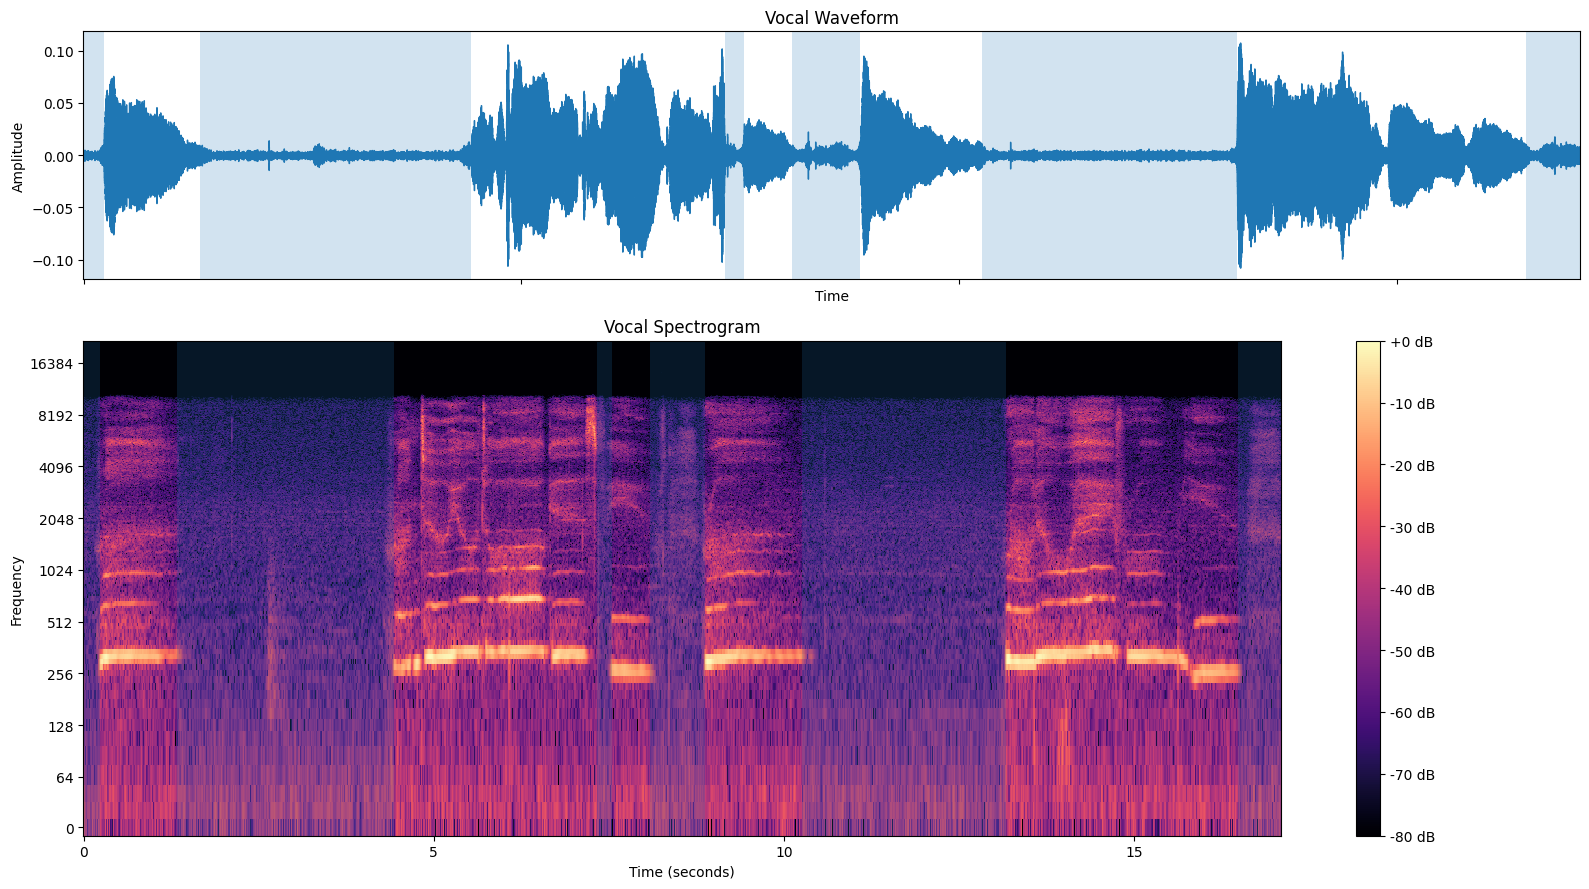


VOCAL TIMING ANALYSIS

LYRIC ALIGNMENT
run             Matched
run             Matched
to              Matched
your            Matched
darkest         Matched
fears           Matched
run             Matched
nothing         Matched
is              Matched
left            Matched
here            Matched

VOWEL EVENTS
run             ah (Extended)      Start: 0.5195 End: 1.28 Duration: 0.7605 Deviation: 19.53 On time (Beat)
run             ah                 Start: 3.5207 End: 3.7414 Duration: 0.2207 Deviation: 20.69 Late (Beat)
to              uw (Extended)      Start: 3.8923 End: 4.2348 Duration: 0.3425 Deviation: 17.25 On time (Sixteenth-note subdivision)
your            ao (Extended)      Start: 4.4321 End: 4.6237 Duration: 0.1916 Deviation: 57.1 Late (Sixteenth-note subdivision)
darkest         aa (Extended)      Start: 4.821 End: 5.625 Duration: 0.8041 Deviation: -54.01 Early (Sixteenth-note subdivision)
darkest         ah                 Start: 6.6409 End: 6.6467 Duration: 0.0058 

In [3]:

import os
import re
import numpy as np
import pandas as pd
import librosa
import librosa.display
import textgrid
import matplotlib.pyplot as plt
from difflib import SequenceMatcher

# ============================================================
# 1. FILE PATHS
# ============================================================

AUDIO_PATH = "/content/drive/MyDrive/VocalTimingCoach/final run - Voice_Audio.wav"
TEXTGRID_PATH = "/content/drive/MyDrive/VocalTimingCoach/voice.TextGrid"
OUTPUT_PATH = "/content/drive/MyDrive/VocalTimingCoach/vocal_timing_report.xlsx"
SPECTROGRAM_PATH = "/content/drive/MyDrive/VocalTimingCoach/vocal_spectrogram.png"

# ============================================================
# 2. USER INPUTS
# ============================================================

LYRICS = input("Paste the exact lyrics sung: ").strip()
BPM = float(input("Song BPM: "))
TIME_SIGNATURE = input("Time signature (e.g. 4/4): ").strip()
SUBDIVISION = input(
    "Smallest subdivision (beat/eighth/sixteenth): "
).strip().lower()

GRID_ZERO = float(input(
    "Time of the first beat in the recording (seconds; enter 0 if it starts at 0): "
))

subdivision_map = {
    "beat": 1,
    "quarter": 1,
    "eighth": 2,
    "sixteenth": 4
}

if BPM <= 0:
    raise ValueError("BPM must be greater than zero.")

if SUBDIVISION not in subdivision_map:
    raise ValueError("Subdivision must be beat, eighth or sixteenth.")

if GRID_ZERO < 0:
    raise ValueError("Beat-zero time cannot be negative.")

try:
    numerator, denominator = map(int, TIME_SIGNATURE.split("/"))
    if numerator <= 0 or denominator <= 0:
        raise ValueError
except:
    raise ValueError("Enter a valid time signature, such as 4/4.")

BEAT_DURATION = 60 / BPM
SUBDIVISIONS_PER_BEAT = subdivision_map[SUBDIVISION]
GRID_STEP = BEAT_DURATION / SUBDIVISIONS_PER_BEAT

# ============================================================
# 3. LOAD AUDIO AND TEXTGRID
# ============================================================

if not os.path.exists(AUDIO_PATH):
    raise FileNotFoundError(f"Audio file not found: {AUDIO_PATH}")

if not os.path.exists(TEXTGRID_PATH):
    raise FileNotFoundError(f"TextGrid file not found: {TEXTGRID_PATH}")

audio, sr = librosa.load(AUDIO_PATH, sr=None, mono=True)
audio_duration = len(audio) / sr

tg = textgrid.TextGrid.fromFile(TEXTGRID_PATH)

print("\n" + "=" * 55)
print("VOCAL TIMING COACH")
print("=" * 55)

print(f"Audio duration: {audio_duration:.2f} seconds")
print(f"Sample rate: {sr} Hz")
print(f"Beat duration: {BEAT_DURATION:.4f} seconds")
print(f"Subdivision duration: {GRID_STEP:.4f} seconds")
print(f"Beat-zero position: {GRID_ZERO:.4f} seconds")

if GRID_ZERO > audio_duration:
    raise ValueError("Beat-zero position is beyond the audio duration.")

# ============================================================
# 4. NORMALISATION
# ============================================================

def normalise(text):
    return re.sub(r"[^a-z']", "", text.lower())

lyrics_words = [
    normalise(w)
    for w in re.findall(r"[A-Za-z']+", LYRICS)
]

lyrics_words = [w for w in lyrics_words if w]

if not lyrics_words:
    raise ValueError("No lyric words were detected.")

def clean_phone(label):
    return re.sub(r"\d+$", "", label.strip().lower())

vowel_labels = {
    "aa", "ae", "ah", "ao", "aw", "ay",
    "eh", "er", "ey", "ih", "iy",
    "ow", "oy", "uh", "uw",
    "a", "e", "i", "o", "u",
    "ə", "ɪ", "ɛ", "æ", "ɑ", "ɔ", "ʊ", "ʌ"
}

# ============================================================
# 5. IDENTIFY WORD AND PHONE TIERS
# ============================================================

tier_data = []

for tier in tg.tiers:
    if not hasattr(tier, "intervals"):
        continue

    intervals = [
        x for x in tier.intervals
        if x.mark.strip()
    ]

    if not intervals:
        continue

    labels = [clean_phone(x.mark) for x in intervals]

    vowel_count = sum(
        label in vowel_labels for label in labels
    )

    word_match_count = sum(
        normalise(x.mark) in lyrics_words
        for x in intervals
    )

    tier_data.append({
        "tier": tier,
        "intervals": intervals,
        "vowel_count": vowel_count,
        "word_match_count": word_match_count
    })

phone_candidates = [
    x for x in tier_data if x["vowel_count"] > 0
]

if not phone_candidates:
    raise ValueError("Could not find a vowel/phone tier.")

phone_data = max(
    phone_candidates,
    key=lambda x: x["vowel_count"]
)

word_candidates = [
    x for x in tier_data if x is not phone_data
]

if not word_candidates:
    raise ValueError("Could not find a separate word tier.")

word_data = max(
    word_candidates,
    key=lambda x: x["word_match_count"]
)

word_intervals = word_data["intervals"]
phone_intervals = phone_data["intervals"]

print("\nWord tier:", word_data["tier"].name)
print("Phone tier:", phone_data["tier"].name)

# ============================================================
# 6. MATCH LYRICS TO ALIGNED WORDS
# ============================================================

grid_words = [
    normalise(x.mark) for x in word_intervals
]

matcher = SequenceMatcher(
    None,
    lyrics_words,
    grid_words,
    autojunk=False
)

word_mapping = {}

for block in matcher.get_matching_blocks():
    for offset in range(block.size):
        word_mapping[block.a + offset] = block.b + offset

# ============================================================
# 7. CALCULATE RHYTHMIC GRID
# ============================================================

# Include grid positions before and after beat zero where
# necessary, while keeping the grid inside the recording.

first_grid_index = int(np.ceil((0 - GRID_ZERO) / GRID_STEP))
last_grid_index = int(np.floor(
    (audio_duration - GRID_ZERO) / GRID_STEP
))

grid_indices = np.arange(
    first_grid_index,
    last_grid_index + 1
)

beat_grid = GRID_ZERO + grid_indices * GRID_STEP

def get_timing(start):

    grid_index = int(round(
        (start - GRID_ZERO) / GRID_STEP
    ))

    expected_time = GRID_ZERO + grid_index * GRID_STEP

    deviation_ms = (start - expected_time) * 1000

    if abs(deviation_ms) <= 20:
        classification = "On time"
    elif deviation_ms < -20:
        classification = "Early"
    else:
        classification = "Late"

    # Describe the rhythmic position within each beat.
    position_in_beat = grid_index % SUBDIVISIONS_PER_BEAT

    if position_in_beat == 0:
        rhythmic_position = "Beat"
    elif SUBDIVISIONS_PER_BEAT == 2:
        rhythmic_position = "Eighth-note offbeat"
    elif position_in_beat == 2:
        rhythmic_position = "Eighth-note offbeat"
    else:
        rhythmic_position = "Sixteenth-note subdivision"

    return (
        expected_time,
        deviation_ms,
        classification,
        rhythmic_position
    )

# ============================================================
# 8. VOWEL EXTENSION DETECTION
# ============================================================

def is_extended(start, end):

    beat_number = np.floor(
        (start - GRID_ZERO) / BEAT_DURATION
    )

    next_boundary = (
        GRID_ZERO + (beat_number + 1) * BEAT_DURATION
    )

    return end > next_boundary + 0.0001

# ============================================================
# 9. BUILD LYRIC AND VOWEL REPORTS
# ============================================================

lyric_report = []
vowel_report = []

for lyric_index, lyric_word in enumerate(lyrics_words):

    if lyric_index not in word_mapping:

        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Missing",
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "Missing",
            "Rhythmic Position": "-"
        })

        continue

    aligned_interval = word_intervals[
        word_mapping[lyric_index]
    ]

    word_start = aligned_interval.minTime
    word_end = aligned_interval.maxTime

    word_phones = []

    for phone in phone_intervals:

        overlap = min(
            word_end, phone.maxTime
        ) - max(
            word_start, phone.minTime
        )

        if overlap > 0:
            word_phones.append(phone)

    word_vowels = [
        phone for phone in word_phones
        if clean_phone(phone.mark) in vowel_labels
    ]

    if not word_vowels:

        lyric_report.append({
            "Lyric Word": lyric_word,
            "Status": "Matched - no vowel detected",
            "Vowel": "-",
            "Start (s)": round(word_start, 4),
            "End (s)": round(word_end, 4)
        })

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": "-",
            "Start (s)": None,
            "End (s)": None,
            "Duration (s)": None,
            "Duration (beats)": None,
            "Extension": "-",
            "Expected Time (s)": None,
            "Deviation (ms)": None,
            "Timing": "No vowel detected",
            "Rhythmic Position": "-"
        })

        continue

    lyric_report.append({
        "Lyric Word": lyric_word,
        "Status": "Matched",
        "Vowel": ", ".join(
            clean_phone(x.mark) for x in word_vowels
        ),
        "Start (s)": round(word_start, 4),
        "End (s)": round(word_end, 4)
    })

    for phone in word_vowels:

        vowel = clean_phone(phone.mark)
        start = phone.minTime
        end = phone.maxTime
        duration = end - start

        (
            expected,
            deviation,
            classification,
            rhythmic_position
        ) = get_timing(start)

        extended = is_extended(start, end)

        vowel_display = vowel + (
            " (Extended)" if extended else ""
        )

        vowel_report.append({
            "Word": lyric_word,
            "Vowel": vowel_display,
            "Start (s)": round(start, 4),
            "End (s)": round(end, 4),
            "Duration (s)": round(duration, 4),
            "Duration (beats)": round(
                duration / BEAT_DURATION, 3
            ),
            "Extension": "Extended" if extended else "-",
            "Expected Time (s)": round(expected, 4),
            "Deviation (ms)": round(deviation, 2),
            "Timing": classification,
            "Rhythmic Position": rhythmic_position
        })

# ============================================================
# 10. SPECTROGRAM + VOCAL ACTIVITY ANALYSIS
# ============================================================

# Calculate short-time RMS energy.
# This gives us a measure of audio energy over time.

FRAME_LENGTH = 2048
HOP_LENGTH = 256

rms = librosa.feature.rms(
    y=audio,
    frame_length=FRAME_LENGTH,
    hop_length=HOP_LENGTH
)[0]

rms_times = librosa.frames_to_time(
    np.arange(len(rms)),
    sr=sr,
    hop_length=HOP_LENGTH
)

rms_db = librosa.amplitude_to_db(
    rms,
    ref=np.max
)

# Adaptive threshold:
# Estimate the quieter background level and compare it with
# the louder parts of the recording.

noise_floor_db = np.percentile(rms_db, 20)
peak_reference_db = np.percentile(rms_db, 95)

activity_threshold_db = max(
    noise_floor_db + 8,
    peak_reference_db - 45
)

# Hysteresis:
# A higher threshold starts a vocal region.
# A lower threshold keeps an existing region active.

start_threshold_db = activity_threshold_db + 3
end_threshold_db = activity_threshold_db

active = np.zeros(len(rms_db), dtype=bool)

currently_active = False

for i, value in enumerate(rms_db):

    if not currently_active:
        if value >= start_threshold_db:
            currently_active = True
    else:
        if value < end_threshold_db:
            currently_active = False

    active[i] = currently_active

# Fill very short gaps between active regions.
# This prevents tiny energy fluctuations from creating
# lots of artificial pauses.

MAX_INTERNAL_GAP = 0.08

for i in range(1, len(active) - 1):

    if active[i]:
        continue

    j = i

    while j < len(active) and not active[j]:
        j += 1

    gap_duration = (
        (j - i) * HOP_LENGTH / sr
    )

    if (
        i > 0
        and j < len(active)
        and active[i - 1]
        and active[j]
        and gap_duration <= MAX_INTERNAL_GAP
    ):
        active[i:j] = True

# Convert inactive regions into pause intervals.

gaps = []

i = 0

while i < len(active):

    if active[i]:
        i += 1
        continue

    start_index = i

    while i < len(active) and not active[i]:
        i += 1

    end_index = i

    gap_start = max(
        0,
        rms_times[start_index] -
        (FRAME_LENGTH / (2 * sr))
    )

    gap_end = min(
        audio_duration,
        rms_times[end_index - 1] +
        (FRAME_LENGTH / (2 * sr))
    )

    duration = gap_end - gap_start

    if duration >= 0.10:

        # Compare gap with aligned word intervals.
        overlapping_words = []

        for lyric_index, word_index in word_mapping.items():

            interval = word_intervals[word_index]

            overlap = min(
                gap_end, interval.maxTime
            ) - max(
                gap_start, interval.minTime
            )

            if overlap > 0:
                overlapping_words.append(
                    lyrics_words[lyric_index]
                )

        if overlapping_words:
            gap_type = "Within aligned word"
        elif gap_end < min(
            [word_intervals[x].minTime for x in word_mapping.values()],
            default=audio_duration
        ):
            gap_type = "Before lyrics"
        elif gap_start > max(
            [word_intervals[x].maxTime for x in word_mapping.values()],
            default=0
        ):
            gap_type = "After lyrics"
        else:
            gap_type = "Between words/phrases"

        gaps.append({
            "Start (s)": round(gap_start, 3),
            "End (s)": round(gap_end, 3),
            "Duration (s)": round(duration, 3),
            "Gap Type": gap_type,
            "Overlapping Words": ", ".join(
                sorted(set(overlapping_words))
            ) if overlapping_words else "-"
        })

# ============================================================
# 11. CREATE SPECTROGRAM VISUALISATION
# ============================================================

D = librosa.stft(
    audio,
    n_fft=2048,
    hop_length=HOP_LENGTH
)

S_db = librosa.amplitude_to_db(
    np.abs(D),
    ref=np.max
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 2]}
)

# Waveform
librosa.display.waveshow(
    audio,
    sr=sr,
    ax=axes[0]
)

axes[0].set_title("Vocal Waveform")
axes[0].set_ylabel("Amplitude")

# Spectrogram
img = librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="log",
    ax=axes[1]
)

axes[1].set_title("Vocal Spectrogram")
axes[1].set_ylabel("Frequency")
axes[1].set_xlabel("Time (seconds)")

fig.colorbar(
    img,
    ax=axes[1],
    format="%+2.0f dB"
)

# Shade detected pauses.
for gap in gaps:
    for ax in axes:
        ax.axvspan(
            gap["Start (s)"],
            gap["End (s)"],
            alpha=0.2
        )

plt.tight_layout()
plt.savefig(
    SPECTROGRAM_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 12. BUILD BEAT GRID REPORT
# ============================================================

beat_grid_report = []

for index, grid_time in enumerate(beat_grid):

    beat_number = (
        (grid_time - GRID_ZERO) / BEAT_DURATION
    )

    beat_grid_report.append({
        "Grid Position": index,
        "Time (s)": round(grid_time, 4),
        "Beat Number": round(beat_number, 3),
        "Time Signature": TIME_SIGNATURE,
        "Subdivision": SUBDIVISION
    })

# ============================================================
# 13. SUMMARY
# ============================================================

early = sum(
    x["Timing"] == "Early" for x in vowel_report
)

on_time = sum(
    x["Timing"] == "On time" for x in vowel_report
)

late = sum(
    x["Timing"] == "Late" for x in vowel_report
)

missing = sum(
    x["Status"] == "Missing" for x in lyric_report
)

extended_count = sum(
    x["Extension"] == "Extended" for x in vowel_report
)

vowel_count = sum(
    x["Vowel"] != "-" for x in vowel_report
)

summary = [
    ("Audio duration (s)", round(audio_duration, 3)),
    ("BPM", BPM),
    ("Time signature", TIME_SIGNATURE),
    ("Subdivision", SUBDIVISION),
    ("Beat-zero position (s)", GRID_ZERO),
    ("Words in lyrics", len(lyrics_words)),
    ("Words aligned", len(word_mapping)),
    ("Missing words", missing),
    ("Vowel events", vowel_count),
    ("Extended vowels", extended_count),
    ("Detected pauses", len(gaps)),
    ("Early vowel onsets", early),
    ("On-time vowel onsets", on_time),
    ("Late vowel onsets", late),
    ("Activity threshold (dB)", round(activity_threshold_db, 2)),
    ("Estimated noise floor (dB)", round(noise_floor_db, 2))
]

print("\n" + "=" * 55)
print("VOCAL TIMING ANALYSIS")
print("=" * 55)

print("\nLYRIC ALIGNMENT")

for row in lyric_report:
    print(
        f"{row['Lyric Word']:15} {row['Status']}"
    )

print("\nVOWEL EVENTS")

for row in vowel_report:
    print(
        f"{row['Word']:15} "
        f"{row['Vowel']:18} "
        f"Start: {row['Start (s)']} "
        f"End: {row['End (s)']} "
        f"Duration: {row['Duration (s)']} "
        f"Deviation: {row['Deviation (ms)']} "
        f"{row['Timing']} "
        f"({row['Rhythmic Position']})"
    )

print("\nDETECTED PAUSES")

for gap in gaps:
    print(gap)

print("\nSUMMARY")

for label, value in summary:
    print(f"{label}: {value}")

# ============================================================
# 14. EXPORT EXCEL REPORT
# ============================================================

with pd.ExcelWriter(OUTPUT_PATH, engine="openpyxl") as writer:

    pd.DataFrame(
        lyric_report
    ).to_excel(
        writer,
        sheet_name="Lyric Alignment",
        index=False
    )

    pd.DataFrame(
        vowel_report
    ).to_excel(
        writer,
        sheet_name="Vowel Timing",
        index=False
    )

    pd.DataFrame(
        gaps,
        columns=[
            "Start (s)",
            "End (s)",
            "Duration (s)",
            "Gap Type",
            "Overlapping Words"
        ]
    ).to_excel(
        writer,
        sheet_name="Low-Energy Gaps",
        index=False
    )

    pd.DataFrame(
        beat_grid_report
    ).to_excel(
        writer,
        sheet_name="Calculated Beat Grid",
        index=False
    )

    pd.DataFrame(
        summary,
        columns=["Metric", "Value"]
    ).to_excel(
        writer,
        sheet_name="Summary",
        index=False
    )

    pd.DataFrame({
        "Time (s)": np.round(rms_times, 4),
        "RMS Energy": rms,
        "Energy (dB)": np.round(rms_db, 2),
        "Vocal Activity": active
    }).to_excel(
        writer,
        sheet_name="Energy Analysis",
        index=False
    )

print("\n" + "=" * 55)
print("ANALYSIS COMPLETE")
print("=" * 55)

print("Excel report:", OUTPUT_PATH)
print("Spectrogram:", SPECTROGRAM_PATH)


In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 5))
plt.plot(df["Time (s)"], df["Energy (dB)"])
plt.xlabel("Time (seconds)")
plt.ylabel("Energy (dB)")
plt.title("Audio Energy Over Time")
plt.grid()
plt.show()

NameError: name 'df' is not defined

<Figure size 1600x500 with 0 Axes>

In [5]:
import pandas as pd
import os

files = os.listdir("/content")
print(files)

['.config', 'drive', 'sample_data']


Saving Voice 261113_175437.m4a to Voice 261113_175437.m4a


/tmp/ipykernel_77020/2009955213.py:14: UserWarning: PySoundFile failed. Trying audioread instead.
  y, sr = librosa.load(audio_file, sr=None, mono=True)
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


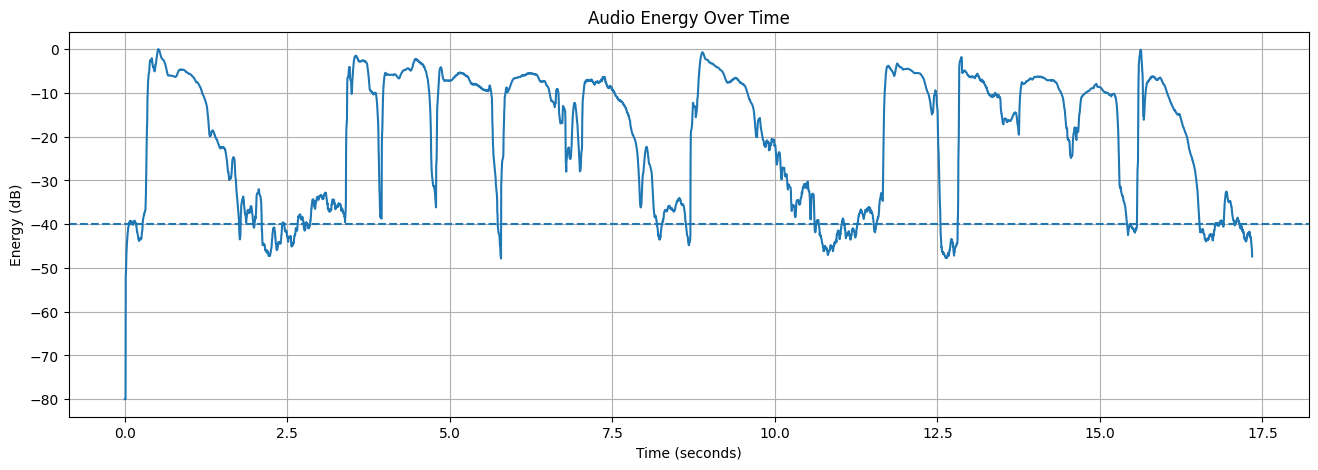

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Analysis complete!
   Time (s)  RMS Energy  Energy (dB) Vocal Activity
0  0.000000    0.000008   -80.000000          Quiet
1  0.003333    0.000010   -80.000000          Quiet
2  0.006667    0.000020   -80.000000          Quiet
3  0.010000    0.000031   -80.000000          Quiet
4  0.013333    0.000972   -51.660843          Quiet


In [6]:
!pip -q install librosa openpyxl

import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# Upload original audio
uploaded = files.upload()
audio_file = next(iter(uploaded))

# Load audio
y, sr = librosa.load(audio_file, sr=None, mono=True)

# Calculate energy
frame_length = 2048
hop_length = 160

rms = librosa.feature.rms(
    y=y,
    frame_length=frame_length,
    hop_length=hop_length
)[0]

times = librosa.frames_to_time(
    np.arange(len(rms)),
    sr=sr,
    hop_length=hop_length
)

# Convert to dB
energy_db = librosa.amplitude_to_db(rms, ref=np.max)

# Initial activity classification
threshold = -40
activity = np.where(energy_db > threshold, "Sound", "Quiet")

# Create table
df = pd.DataFrame({
    "Time (s)": times,
    "RMS Energy": rms,
    "Energy (dB)": energy_db,
    "Vocal Activity": activity
})

# Plot
plt.figure(figsize=(16, 5))
plt.plot(times, energy_db)
plt.axhline(threshold, linestyle="--")
plt.xlabel("Time (seconds)")
plt.ylabel("Energy (dB)")
plt.title("Audio Energy Over Time")
plt.grid()
plt.show()

# Export
output_file = "vocal_energy_analysis.xlsx"
df.to_excel(output_file, index=False)

files.download(output_file)

print("Analysis complete!")
print(df.head())

In [7]:
import numpy as np
import pandas as pd

# Use the energy data already calculated
threshold = -40
active = df["Energy (dB)"].values > threshold
times = df["Time (s)"].values

# Fill gaps shorter than 0.15 seconds
max_gap = int(0.15 / (times[1] - times[0]))

for i in range(1, len(active)):
    pass

# Find continuous regions
regions = []
in_region = False

for i, value in enumerate(active):
    if value and not in_region:
        start = times[i]
        in_region = True
    elif not value and in_region:
        end = times[i]
        if end - start >= 0.12:
            regions.append((round(start, 3), round(end, 3)))
        in_region = False

if in_region:
    regions.append((round(start, 3), round(times[-1], 3)))

result = pd.DataFrame(regions, columns=["Start (s)", "End (s)"])
result["Duration (s)"] = result["End (s)"] - result["Start (s)"]

print("DETECTED SOUND REGIONS")
display(result)

result.to_excel("detected_sound_regions.xlsx", index=False)
files.download("detected_sound_regions.xlsx")

DETECTED SOUND REGIONS


,Start (s),End (s),Duration (s)
0,0.273,1.757,1.484
1,1.783,1.977,0.194
2,2.853,5.737,2.884
3,5.790,8.187,2.397
4,8.267,8.633,0.366
5,8.703,10.610,1.907
6,11.273,11.520,0.247
7,11.563,12.550,0.987
8,12.813,15.420,2.607
9,15.573,16.533,0.960


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# Merge regions separated by gaps of 0.30 seconds or less
merged = []

for start, end in regions:
    if not merged or start - merged[-1][1] > 0.30:
        merged.append([start, end])
    else:
        merged[-1][1] = end

final_regions = pd.DataFrame(
    merged,
    columns=["Start (s)", "End (s)"]
)

final_regions["Duration (s)"] = (
    final_regions["End (s)"] - final_regions["Start (s)"]
)

display(final_regions)

final_regions.to_excel(
    "final_energy_regions.xlsx", index=False
)

files.download("final_energy_regions.xlsx")

,Start (s),End (s),Duration (s)
0,0.273,1.977,1.704
1,2.853,10.610,7.757
2,11.273,16.533,5.260
3,16.907,17.073,0.166


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>